# benchmark

In [2]:
from __future__ import annotations

from dataclasses import dataclass
import numpy as np


@dataclass(frozen=True)
class CoffeeShopParams:
    capacity: int
    arrival_rate: float
    service_rate: float
    dine_in_price: float
    dine_in_cost: float
    takeout_cost: float
    dine_in_value: float
    takeout_value: float
    price_sensitivity: float
    takeout_price_grid: np.ndarray


def choice_probabilities(n: int, p: float, x: CoffeeShopParams):
    u_t = x.takeout_value - x.price_sensitivity * p
    if n < x.capacity:
        u_d = x.dine_in_value - x.price_sensitivity * x.dine_in_price
        u = np.array([u_d, u_t, 0.0])
        w = np.exp(u - u.max())
        q_d, q_t, q_0 = w / w.sum()
    else:
        u = np.array([u_t, 0.0])
        w = np.exp(u - u.max())
        q_t, q_0 = w / w.sum()
        q_d = 0.0
    return float(q_d), float(q_t), float(q_0)


def build_uniformized_mdp(x: CoffeeShopParams):
    K, lam, mu = x.capacity, x.arrival_rate, x.service_rate
    prices = np.asarray(x.takeout_price_grid, dtype=float)
    S, A = K + 1, len(prices)
    nu = (lam + K * mu) * 1.000001

    P = np.zeros((S, A, S))
    r = np.zeros((S, A))
    dine_margin = x.dine_in_price - x.dine_in_cost

    for n in range(S):
        for a, p in enumerate(prices):
            q_d, q_t, q_0 = choice_probabilities(n, p, x)
            r[n, a] = lam * (q_d * dine_margin + q_t * (p - x.takeout_cost))

            if n < K:
                P[n, a, n + 1] += lam * q_d / nu
                P[n, a, n] += lam * (q_t + q_0) / nu
            else:
                P[n, a, n] += lam / nu

            if n > 0:
                P[n, a, n - 1] += n * mu / nu

            P[n, a, n] += 1.0 - (lam + n * mu) / nu

    if not np.allclose(P.sum(axis=2), 1.0, atol=1e-11):
        raise RuntimeError("Transition rows do not sum to one.")
    return prices, P, r, nu


def relative_value_iteration(P, reward_rate, nu, tol=1e-11, max_iter=200000):
    reward = reward_rate / nu
    S = reward.shape[0]
    h = np.zeros(S)

    for iteration in range(1, max_iter + 1):
        Q = reward + np.einsum("nas,s->na", P, h)
        v = Q.max(axis=1)
        h_new = v - v[0]
        d = h_new - h
        if d.max() - d.min() < tol:
            h = h_new
            break
        h = h_new
    else:
        raise RuntimeError("Relative value iteration did not converge.")

    Q = reward + np.einsum("nas,s->na", P, h)
    policy = Q.argmax(axis=1)
    residual = Q.max(axis=1) - h
    g = nu * 0.5 * (residual.min() + residual.max())
    return policy, h, float(g), iteration


def stationary_distribution(P_pi):
    S = P_pi.shape[0]
    A = P_pi.T - np.eye(S)
    b = np.zeros(S)
    A[-1, :] = 1.0
    b[-1] = 1.0
    pi = np.linalg.solve(A, b)
    pi = np.maximum(pi, 0.0)
    return pi / pi.sum()


def evaluate_policy(P, reward_rate, policy):
    idx = np.arange(len(policy))
    P_pi = P[idx, policy, :]
    r_pi = reward_rate[idx, policy]
    pi = stationary_distribution(P_pi)
    return {
        "stationary_distribution": pi,
        "average_profit_rate": float(pi @ r_pi),
        "full_probability": float(pi[-1]),
        "mean_occupied_seats": float(pi @ np.arange(len(pi))),
    }


def solve_coffee_shop(x: CoffeeShopParams):
    prices, P, r, nu = build_uniformized_mdp(x)
    policy, h, g, iterations = relative_value_iteration(P, r, nu)
    ev = evaluate_policy(P, r, policy)
    return {
        "optimal_prices": prices[policy],
        "policy_indices": policy,
        "relative_values": h,
        "bellman_average_profit_rate": g,
        "evaluated_average_profit_rate": ev["average_profit_rate"],
        "stationary_distribution": ev["stationary_distribution"],
        "full_probability": ev["full_probability"],
        "mean_occupied_seats": ev["mean_occupied_seats"],
        "iterations": iterations,
    }


def best_constant_price(x: CoffeeShopParams):
    prices, P, r, _ = build_uniformized_mdp(x)
    best = None
    for a, p in enumerate(prices):
        policy = np.full(x.capacity + 1, a, dtype=int)
        ev = evaluate_policy(P, r, policy)
        candidate = {"price": float(p), **ev}
        if best is None or candidate["average_profit_rate"] > best["average_profit_rate"]:
            best = candidate
    return best


if __name__ == "__main__":
    params = CoffeeShopParams(
        capacity=10,
        arrival_rate=15.0,
        service_rate=1.0 / 0.75,  # mean stay = 45 minutes
        dine_in_price=6.00,
        dine_in_cost=1.50,
        takeout_cost=1.70,
        dine_in_value=5.00,
        takeout_value=4.00,
        price_sensitivity=0.70,
        takeout_price_grid=np.linspace(2.00, 8.00, 121),
    )

    result = solve_coffee_shop(params)
    benchmark = best_constant_price(params)

    print("Optimal occupancy-dependent takeout prices")
    print("occupied seats | takeout price")
    for n, p in enumerate(result["optimal_prices"]):
        print(f"{n:14d} | ${p:6.2f}")

    dynamic_profit = result["evaluated_average_profit_rate"]
    constant_profit = benchmark["average_profit_rate"]

    print("\nDynamic policy")
    print(f"Average profit per hour : ${dynamic_profit:.4f}")
    print(f"Probability cafe is full: {result['full_probability']:.4f}")
    print(f"Mean occupied seats      : {result['mean_occupied_seats']:.4f}")

    print("\nBest constant-price benchmark")
    print(f"Takeout price            : ${benchmark['price']:.2f}")
    print(f"Average profit per hour  : ${constant_profit:.4f}")

    improvement = 100.0 * (dynamic_profit / constant_profit - 1.0)
    print(f"\nProfit improvement from dynamic pricing: {improvement:.3f}%")


Optimal occupancy-dependent takeout prices
occupied seats | takeout price
             0 | $  6.40
             1 | $  6.40
             2 | $  6.40
             3 | $  6.35
             4 | $  6.35
             5 | $  6.30
             6 | $  6.25
             7 | $  6.15
             8 | $  6.00
             9 | $  5.70
            10 | $  5.20

Dynamic policy
Average profit per hour : $49.3254
Probability cafe is full: 0.0506
Mean occupied seats      : 6.0217

Best constant-price benchmark
Takeout price            : $6.05
Average profit per hour  : $49.1646

Profit improvement from dynamic pricing: 0.327%


# study the policy function

In [3]:
# ============================================================
# Policy-function sensitivity analysis for the base model
# Final simplified version:
#   1. No heatmaps.
#   2. Policy is plotted only against occupied seats n.
#   3. Different curves represent different parameter values.
#   4. Policy is shown as p*(n) / p_d.
#   5. Also plots dynamic-pricing profit gain.
# ============================================================

from dataclasses import replace
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D


# ------------------------------------------------------------
# Helper: update parameter and optionally rescale price grid
# ------------------------------------------------------------

def update_params_for_sweep(
    base_params: CoffeeShopParams,
    param_name: str,
    param_value,
    rescale_price_grid_when_pd_changes: bool = True,
):
    """
    Returns a modified parameter object.

    When dine_in_price changes, it is usually better to rescale the
    takeout-price grid proportionally, so that the feasible ratio p / p_d
    is comparable across different dine-in prices.
    """
    if param_name == "dine_in_price" and rescale_price_grid_when_pd_changes:
        base_ratio_grid = base_params.takeout_price_grid / base_params.dine_in_price
        new_takeout_price_grid = base_ratio_grid * param_value

        return replace(
            base_params,
            dine_in_price=param_value,
            takeout_price_grid=new_takeout_price_grid
        )

    return replace(base_params, **{param_name: param_value})


# ------------------------------------------------------------
# Helper: solve dynamic policy and best constant benchmark
# ------------------------------------------------------------

def solve_with_benchmark(params: CoffeeShopParams):
    """
    Solves the dynamic occupancy-dependent policy and the best constant
    off-premise price benchmark.
    """
    dynamic = solve_coffee_shop(params)
    constant = best_constant_price(params)

    dynamic_profit = dynamic["evaluated_average_profit_rate"]
    constant_profit = constant["average_profit_rate"]

    gain_pct = 100.0 * (dynamic_profit / constant_profit - 1.0)

    return {
        "dynamic": dynamic,
        "constant": constant,
        "dynamic_profit": dynamic_profit,
        "constant_profit": constant_profit,
        "gain_pct": gain_pct,
    }

from matplotlib.lines import Line2D


def plot_stationary_distribution_comparison(
    base_params: CoffeeShopParams,
    param_name: str,
    param_values,
    title=None,
    use_occupancy_rate=False,
):
    """
    Compare stationary seat-occupancy distributions under:

        solid line  = optimal dynamic pricing
        dashed line = best constant pricing

    Color identifies the parameter value.
    """

    fig, ax = plt.subplots(figsize=(11.5, 4.8))

    parameter_handles = []
    parameter_labels = []

    for val in param_values:

        # Update the parameter
        params = update_params_for_sweep(
            base_params=base_params,
            param_name=param_name,
            param_value=val,
        )

        # Solve dynamic and constant policies
        out = solve_with_benchmark(params)

        pi_dynamic = np.asarray(
            out["dynamic"]["stationary_distribution"]
        )

        pi_constant = np.asarray(
            out["constant"]["stationary_distribution"]
        )

        K = params.capacity
        n = np.arange(K + 1)

        if use_occupancy_rate:
            x_axis = n / K
            x_label = "Occupancy rate $n/K$"
        else:
            x_axis = n
            x_label = "Occupied seats $n$"

        # ----------------------------------------------------
        # Dynamic pricing
        # ----------------------------------------------------
        line, = ax.plot(
            x_axis,
            pi_dynamic,
            marker="o",
            markersize=4,
            linewidth=1.8
        )

        color = line.get_color()

        # Save color for parameter legend
        parameter_handles.append(
            Line2D(
                [0], [0],
                color=color,
                linewidth=1.8
            )
        )

        parameter_labels.append(f"{val:.3g}")

        # ----------------------------------------------------
        # Best constant pricing
        # ----------------------------------------------------
        ax.plot(
            x_axis,
            pi_constant,
            linestyle="--",
            linewidth=1.8,
            color=color
        )

    # --------------------------------------------------------
    # Labels
    # --------------------------------------------------------
    ax.set_xlabel(x_label)
    ax.set_ylabel("Stationary probability")

    if title is None:
        title = (
            f"Stationary occupancy distributions under "
            f"different {param_name} values"
        )

    ax.set_title(title)

    ax.grid(True, alpha=0.3)

    # --------------------------------------------------------
    # Parameter-value legend
    # --------------------------------------------------------
    parameter_legend = ax.legend(
        handles=parameter_handles,
        labels=parameter_labels,
        title=param_name,
        loc="upper left",
        bbox_to_anchor=(1.02, 1.00),
        frameon=True
    )

    ax.add_artist(parameter_legend)

    # --------------------------------------------------------
    # Policy-style legend
    # --------------------------------------------------------
    policy_handles = [
        Line2D(
            [0], [0],
            color="black",
            linestyle="-",
            marker="o",
            linewidth=1.8,
            label="Dynamic pricing"
        ),
        Line2D(
            [0], [0],
            color="black",
            linestyle="--",
            linewidth=1.8,
            label="Constant pricing"
        )
    ]

    ax.legend(
        handles=policy_handles,
        title="Pricing policy",
        loc="upper left",
        bbox_to_anchor=(1.02, 0.45),
        frameon=True
    )

    # Leave space for external legends
    plt.tight_layout(rect=[0, 0, 0.78, 1])

    plt.show()


from matplotlib.lines import Line2D


def plot_stationary_distribution_difference(
    base_params: CoffeeShopParams,
    param_name: str,
    param_values,
    title=None,
    use_occupancy_rate=False,
):
    """
    Plot the difference in stationary occupancy distributions:

        delta_pi(n) = pi_dynamic(n) - pi_constant(n)

    Color identifies the parameter value.
    """

    fig, ax = plt.subplots(figsize=(11.5, 4.8))

    parameter_handles = []
    parameter_labels = []

    for val in param_values:

        # Update parameter
        params = update_params_for_sweep(
            base_params=base_params,
            param_name=param_name,
            param_value=val,
        )

        # Solve model
        out = solve_with_benchmark(params)

        pi_dynamic = np.asarray(out["dynamic"]["stationary_distribution"], dtype=float)
        pi_constant = np.asarray(out["constant"]["stationary_distribution"], dtype=float)

        delta_pi = pi_dynamic - pi_constant

        K = params.capacity
        n = np.arange(K + 1)

        if use_occupancy_rate:
            x_axis = n / K
            x_label = "Occupancy rate $n/K$"
        else:
            x_axis = n
            x_label = "Occupied seats $n$"

        line, = ax.plot(
            x_axis,
            delta_pi,
            marker="o",
            markersize=4,
            linewidth=1.8,
        )

        parameter_handles.append(
            Line2D(
                [0], [0],
                color=line.get_color(),
                linewidth=1.8
            )
        )
        parameter_labels.append(f"{val:.3g}")

    # Zero line
    ax.axhline(0.0, linestyle="--", linewidth=1.0, color="black")

    ax.set_xlabel(x_label)
    ax.set_ylabel(r"$\pi^{D}(n) - \pi^{C}(n)$")

    if title is None:
        title = (
            f"Difference in stationary occupancy distributions\n"
            f"(dynamic pricing minus constant pricing)"
        )

    ax.set_title(title)
    ax.grid(True, alpha=0.3)

    # Legend outside plot
    ax.legend(
        handles=parameter_handles,
        labels=parameter_labels,
        title=param_name,
        loc="upper left",
        bbox_to_anchor=(1.02, 1.00),
        frameon=True
    )

    plt.tight_layout(rect=[0, 0, 0.82, 1])
    plt.show()
# ------------------------------------------------------------
# One-way sweep
# ------------------------------------------------------------

def one_way_policy_sweep_for_curves(
    base_params: CoffeeShopParams,
    param_name: str,
    param_values,
    rescale_price_grid_when_pd_changes: bool = True,
):
    """
    Varies one parameter and records:
        1. optimal policy ratio p*(n) / p_d;
        2. profit gain from dynamic pricing.

    Returns
    -------
    policy_df:
        Long-format data for plotting p*(n) / p_d against n.

    summary_df:
        One row per parameter value, including dynamic profit,
        constant-profit benchmark, and gain percentage.
    """
    policy_rows = []
    summary_rows = []

    for val in param_values:
        params = update_params_for_sweep(
            base_params=base_params,
            param_name=param_name,
            param_value=val,
            rescale_price_grid_when_pd_changes=rescale_price_grid_when_pd_changes,
        )

        out = solve_with_benchmark(params)

        optimal_prices = np.asarray(out["dynamic"]["optimal_prices"], dtype=float)
        optimal_price_ratio = optimal_prices / params.dine_in_price
        constant_price_ratio = (
    out["constant"]["price"] / params.dine_in_price
)  ## 20260923

        K = params.capacity

        for n in range(K + 1):
            policy_rows.append({
                "parameter": param_name,
                "parameter_value": val,
                "occupied_seats": n,
                "occupancy_rate": n / K,
                "optimal_price_ratio": float(optimal_price_ratio[n]),
                "constant_price_ratio": float(constant_price_ratio)
            })

        summary_rows.append({
            "parameter": param_name,
            "parameter_value": val,
            "dynamic_profit": out["dynamic_profit"],
            "constant_profit": out["constant_profit"],
            "gain_pct": out["gain_pct"],
            "best_constant_price": out["constant"]["price"],
            "best_constant_price_ratio": out["constant"]["price"] / params.dine_in_price,
            "dynamic_full_probability": out["dynamic"]["full_probability"],
            "constant_full_probability": out["constant"]["full_probability"],
            "dynamic_mean_occupied_seats": out["dynamic"]["mean_occupied_seats"],
            "constant_mean_occupied_seats": out["constant"]["mean_occupied_seats"],
            "ratio_empty": float(optimal_price_ratio[0]),
            "ratio_half": float(optimal_price_ratio[int(round(K / 2))]),
            "ratio_near_full": float(optimal_price_ratio[K - 1]),
            "ratio_full": float(optimal_price_ratio[K]),
            "near_full_minus_empty_ratio": float(optimal_price_ratio[K - 1] - optimal_price_ratio[0]),
            "full_minus_near_full_ratio": float(optimal_price_ratio[K] - optimal_price_ratio[K - 1]),
        })

    return pd.DataFrame(policy_rows), pd.DataFrame(summary_rows)


# ------------------------------------------------------------
# Plot policy ratio p*(n) / p_d against occupied seats n
# ------------------------------------------------------------

# def plot_policy_ratio_against_n(
#     policy_df,
#     title=None,
#     use_occupancy_rate=False,
# ):
#     """
#     Plots p*(n) / p_d against occupied seats n.

#     Different curves represent different parameter values.
#     """
#     param_name = policy_df["parameter"].iloc[0]

#     plt.figure(figsize=(8, 5))

#     for val, df in policy_df.groupby("parameter_value"):
#         df = df.sort_values("occupied_seats")

#         if use_occupancy_rate:
#             x_axis = df["occupancy_rate"]
#             x_label = "Occupancy rate n/K"
#         else:
#             x_axis = df["occupied_seats"]
#             x_label = "Occupied seats n"

#         plt.plot(
#             x_axis,
#             df["optimal_price_ratio"],
#             marker="o",
#             linewidth=1.8,
#             label=f"{param_name} = {val:.3g}"
#         )

#     #plt.axhline(1.0, linestyle="--", linewidth=1.0)
#     plt.xlabel(x_label)
#     plt.ylabel("Optimal off-premise price ratio p*(n) / p_d")

#     if title is None:
#         title = f"Optimal policy ratio under different {param_name} values"

#     plt.title(title)
#     plt.legend()
#     plt.grid(True, alpha=0.3)
#     plt.tight_layout()
#     plt.show()

# def plot_policy_ratio_against_n(
#     policy_df,
#     title=None,
#     use_occupancy_rate=False,
# ):
#     """
#     Plots dynamic p*(n) / p_d and the best constant-price benchmark
#     against occupied seats n.

#     Solid lines: optimal dynamic pricing.
#     Dashed lines: best constant pricing.
#     """
#     param_name = policy_df["parameter"].iloc[0]

#     plt.figure(figsize=(8, 5))

#     for val, df in policy_df.groupby("parameter_value"):
#         df = df.sort_values("occupied_seats")

#         if use_occupancy_rate:
#             x_axis = df["occupancy_rate"]
#             x_label = "Occupancy rate n/K"
#         else:
#             x_axis = df["occupied_seats"]
#             x_label = "Occupied seats n"

#         # Dynamic pricing
#         line, = plt.plot(
#             x_axis,
#             df["optimal_price_ratio"],
#             marker="o",
#             linewidth=1.8,
#             label=f"{param_name} = {val:.3g}"
#         )

#         # Best constant pricing
#         constant_ratio = df["constant_price_ratio"].iloc[0]

#         plt.plot(
#             x_axis,
#             np.full(len(df), constant_ratio),
#             linestyle="--",
#             linewidth=1.5,
#             color=line.get_color(),
#             label=f"{param_name} = {val:.3g} (constant)"
#         )

#     plt.xlabel(x_label)
#     plt.ylabel("Off-premise price ratio p / p_d")

#     if title is None:
#         title = f"Pricing policies under different {param_name} values"

#     plt.title(title)
#     plt.legend()
#     plt.grid(True, alpha=0.3)
#     plt.tight_layout()
#     plt.show()

def plot_policy_ratio_against_n(
    policy_df,
    title=None,
    use_occupancy_rate=False,
):
    """
    Plots dynamic p*(n) / p_d and the best constant-price benchmark.

    Color:
        identifies the parameter value.

    Line style:
        solid + markers = optimal dynamic pricing;
        dashed = best constant pricing.
    """

    param_name = policy_df["parameter"].iloc[0]

    fig, ax = plt.subplots(figsize=(12, 5))

    parameter_handles = []
    parameter_labels = []

    if use_occupancy_rate:
        x_label = "Occupancy rate n/K"
    else:
        x_label = "Occupied seats n"

    for val, df in policy_df.groupby("parameter_value"):
        df = df.sort_values("occupied_seats")

        if use_occupancy_rate:
            x_axis = df["occupancy_rate"]
        else:
            x_axis = df["occupied_seats"]

        # ----------------------------------------------------
        # Dynamic pricing policy
        # ----------------------------------------------------
        line, = ax.plot(
            x_axis,
            df["optimal_price_ratio"],
            marker="o",
            linewidth=1.8
        )

        # Save one handle for the parameter-value legend
        parameter_handles.append(line)
        parameter_labels.append(f"{val:.3g}")

        # ----------------------------------------------------
        # Best constant-price policy
        # Same color as corresponding dynamic policy
        # ----------------------------------------------------
        constant_ratio = df["constant_price_ratio"].iloc[0]

        ax.plot(
            x_axis,
            np.full(len(df), constant_ratio),
            linestyle="--",
            linewidth=1.5,
            color=line.get_color()
        )

    # --------------------------------------------------------
    # Axis labels
    # --------------------------------------------------------
    ax.set_xlabel(x_label)
    ax.set_ylabel("Off-premise price ratio $p/p_d$")

    if title is None:
        title = f"Pricing policies under different {param_name} values"

    ax.set_title(title)
    ax.grid(True, alpha=0.3)

    # --------------------------------------------------------
    # Legend 1: parameter values / colors
    # --------------------------------------------------------
    parameter_legend = ax.legend(
        handles=parameter_handles,
        labels=parameter_labels,
        title=param_name,
        loc="upper left",
        bbox_to_anchor=(1.02, 1.00),
        frameon=True
    )

    # Keep this legend when adding the second legend
    ax.add_artist(parameter_legend)

    # --------------------------------------------------------
    # Legend 2: pricing-policy line styles
    # --------------------------------------------------------
    style_handles = [
        Line2D(
            [0], [0],
            linestyle="-",
            marker="o",
            linewidth=1.8,
            color="black",
            label="Dynamic pricing"
        ),
        Line2D(
            [0], [0],
            linestyle="--",
            linewidth=1.5,
            color="black",
            label="Constant pricing"
        )
    ]

    ax.legend(
        handles=style_handles,
        title="Pricing policy",
        loc="upper left",
        bbox_to_anchor=(1.02, 0.42),
        frameon=True
    )

    # Leave space on the right for legends
    plt.tight_layout(rect=[0, 0, 0.76, 1])

    plt.show()
# ------------------------------------------------------------
# Plot gain from dynamic pricing
# ------------------------------------------------------------

def plot_dynamic_pricing_gain(
    summary_df,
    title=None,
):
    """
    Plots the profit gain from dynamic pricing relative to the best constant
    off-premise price.

    This is the only plot where the parameter value is used on the x-axis.
    """
    param_name = summary_df["parameter"].iloc[0]
    df = summary_df.sort_values("parameter_value")

    plt.figure(figsize=(7, 4.8))

    plt.plot(
        df["parameter_value"],
        df["gain_pct"],
        marker="o",
        linewidth=1.8
    )

    #plt.axhline(0.0, linestyle="--", linewidth=1.0)
    plt.xlabel(param_name)
    plt.ylabel("Profit gain from dynamic pricing (%)")

    if title is None:
        title = f"Dynamic-pricing profit gain under different {param_name} values"

    plt.title(title)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()


# ------------------------------------------------------------
# Optional: plot congestion comparison
# ------------------------------------------------------------

def plot_full_probability_comparison(
    summary_df,
    title=None,
):
    """
    Optional diagnostic plot:
    compares full-capacity probability under dynamic pricing and best constant pricing.
    """
    param_name = summary_df["parameter"].iloc[0]
    df = summary_df.sort_values("parameter_value")

    plt.figure(figsize=(7, 4.8))

    plt.plot(
        df["parameter_value"],
        df["dynamic_full_probability"],
        marker="o",
        linewidth=1.8,
        label="Dynamic pricing"
    )

    plt.plot(
        df["parameter_value"],
        df["constant_full_probability"],
        marker="o",
        linewidth=1.8,
        label="Best constant price"
    )

    plt.xlabel(param_name)
    plt.ylabel("Probability cafe is full")

    if title is None:
        title = f"Full-capacity probability under different {param_name} values"

    plt.title(title)
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()


# ------------------------------------------------------------
# Convenience function for one sweep
# ------------------------------------------------------------

def run_and_plot_one_sweep(
    base_params: CoffeeShopParams,
    param_name: str,
    param_values,
    policy_title: str,
    gain_title: str,
    use_occupancy_rate: bool = False,
):
    """
    Runs one parameter sweep and produces:
        1. policy ratio curves against n;
        2. profit-gain plot.
    """
    policy_df, summary_df = one_way_policy_sweep_for_curves(
        base_params=base_params,
        param_name=param_name,
        param_values=param_values,
    )

    plot_policy_ratio_against_n(
        policy_df,
        title=policy_title,
        use_occupancy_rate=use_occupancy_rate,
    )

    plot_dynamic_pricing_gain(
        summary_df,
        title=gain_title,
    )

    return policy_df, summary_df

# Compare the results under different parameters

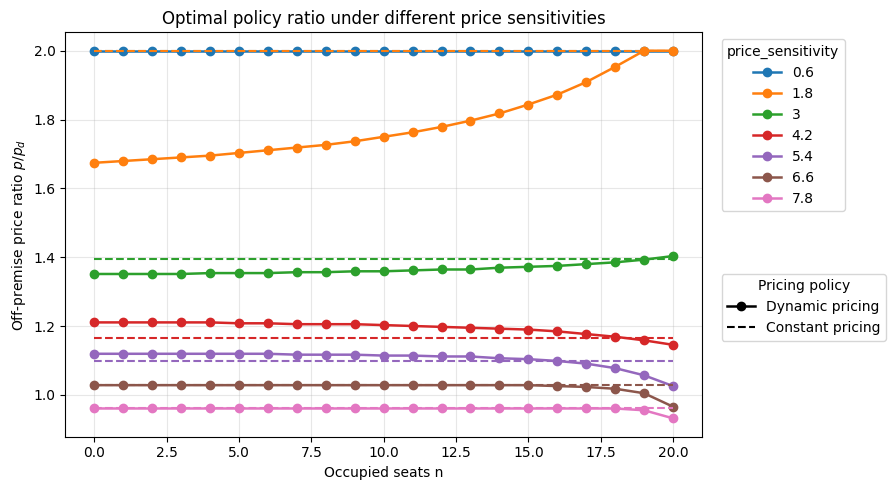

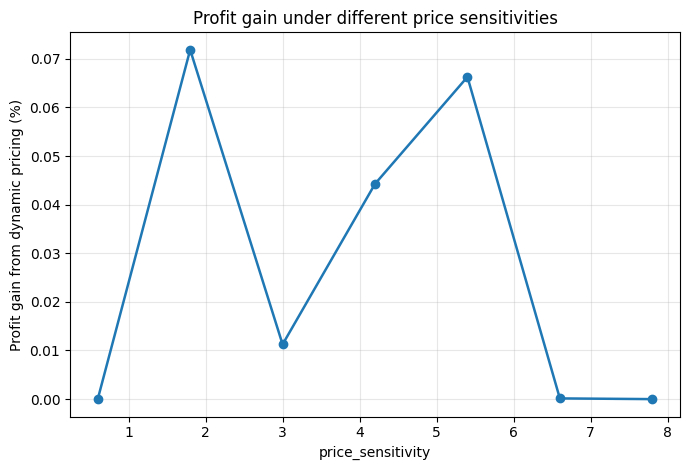

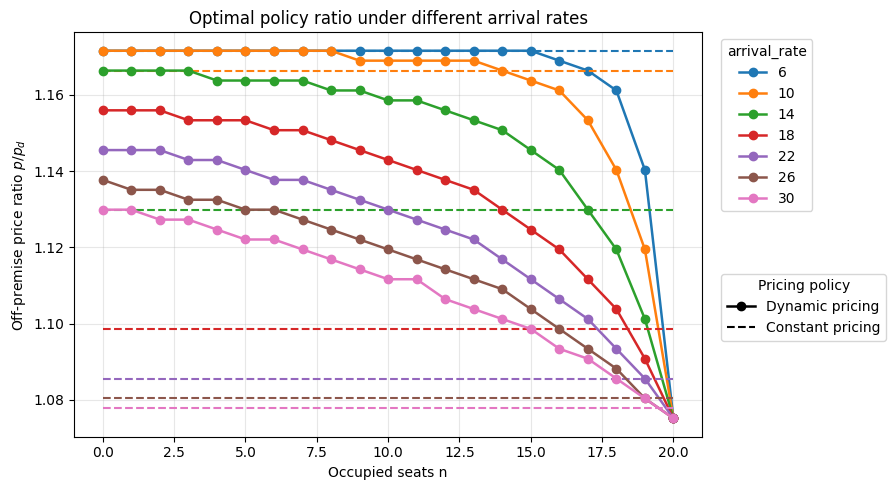

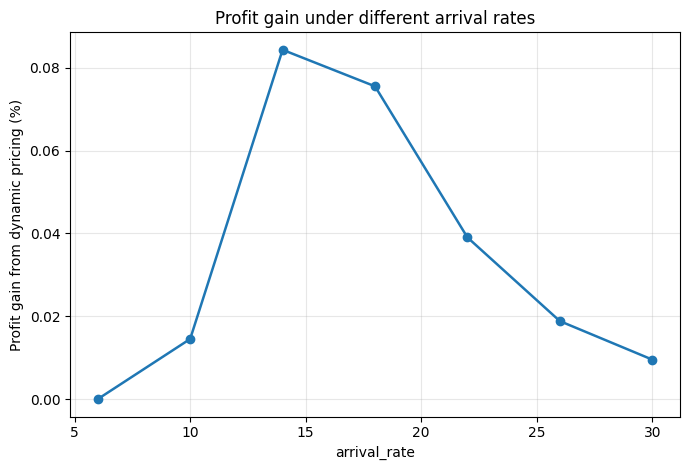

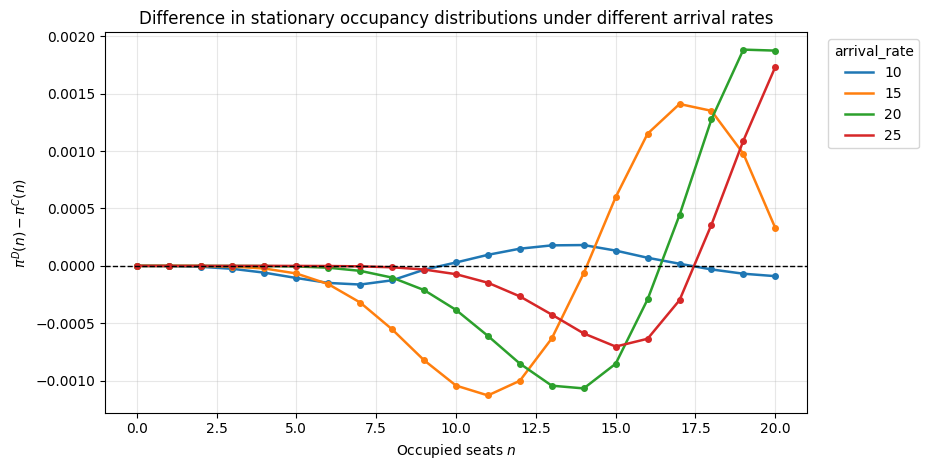

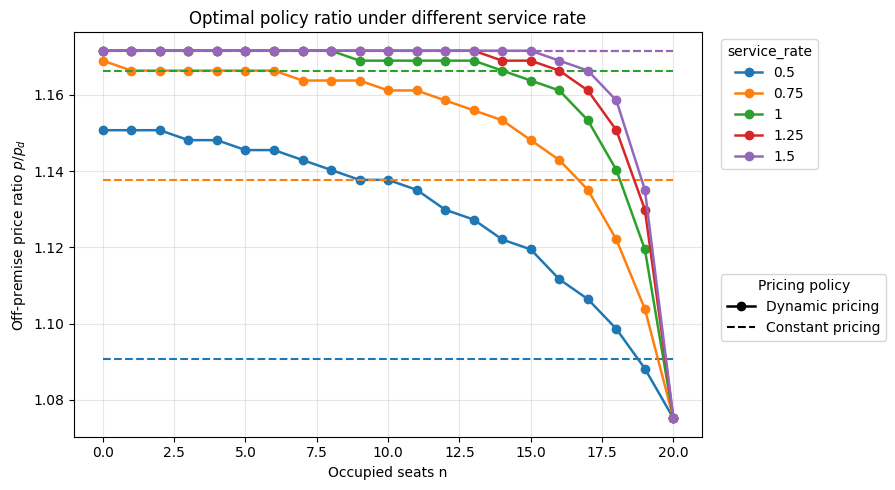

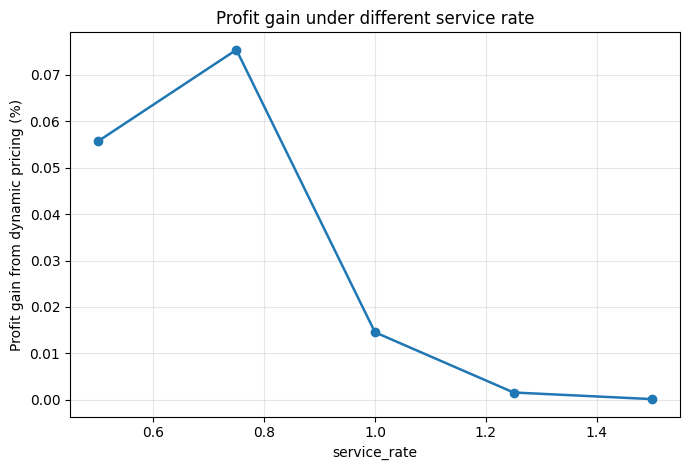

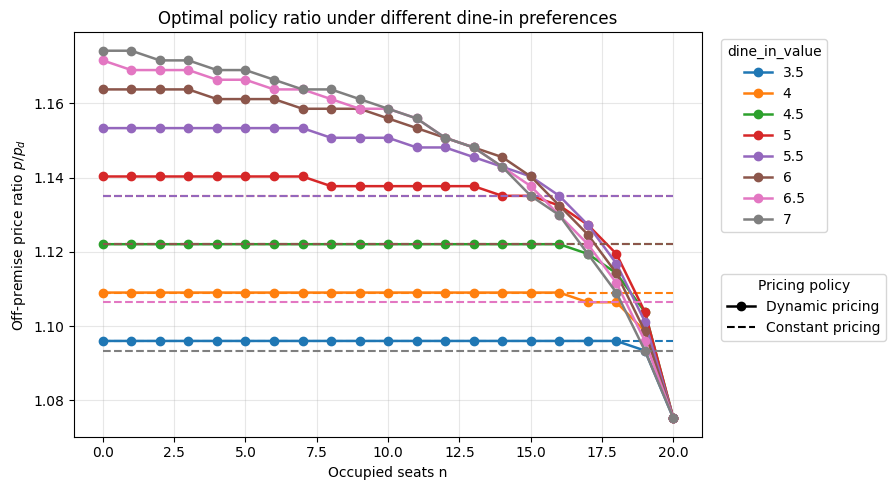

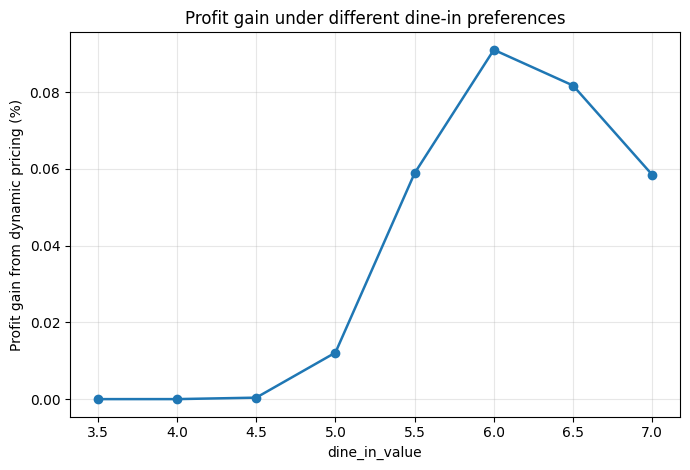

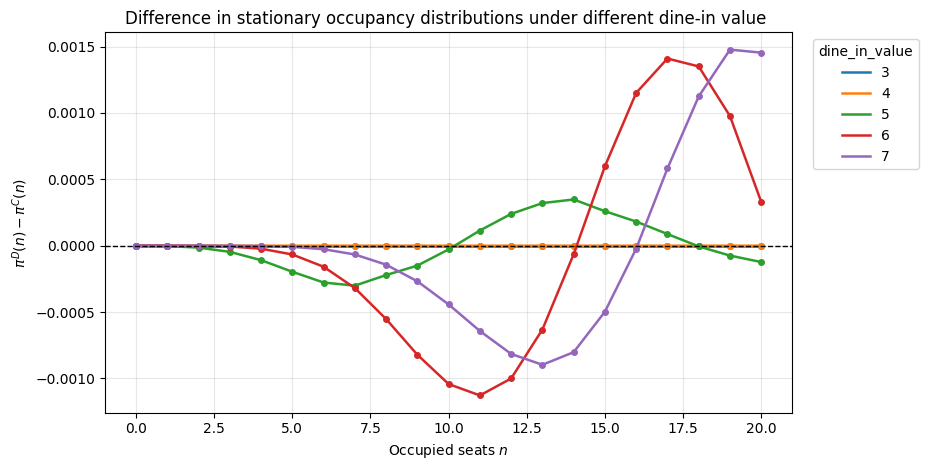

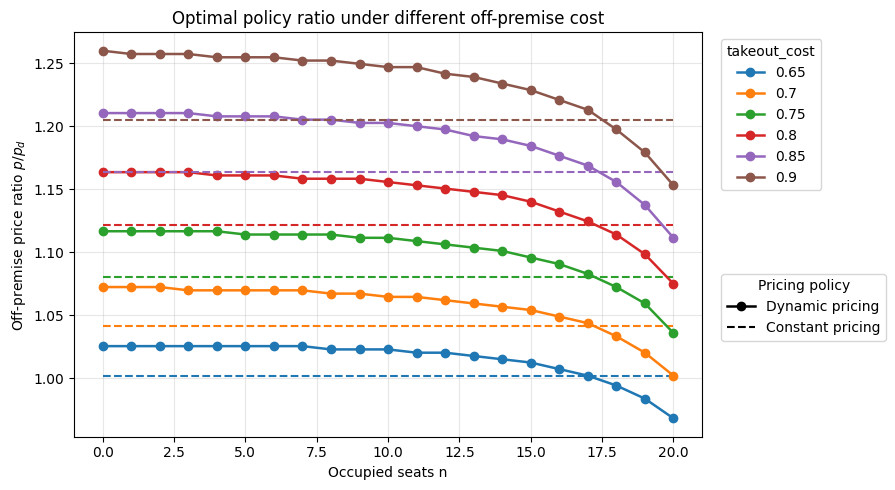

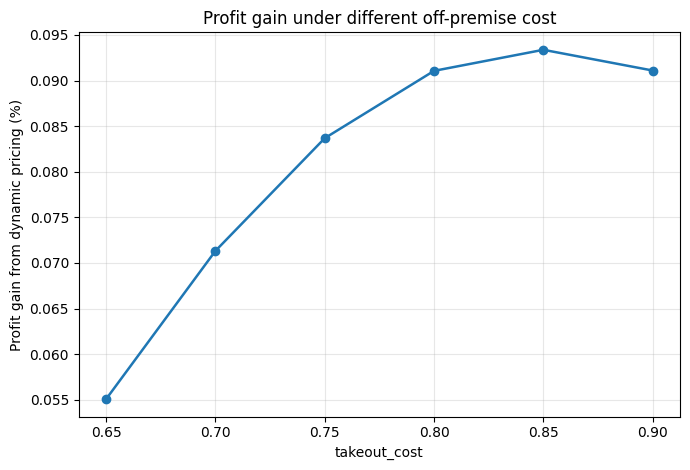

In [20]:
if __name__ == "__main__":
    base_params = CoffeeShopParams(
        capacity=20,
        arrival_rate= 15,
        service_rate= 1/1.5,  # a typical dining can be like 1 hour and hafl
        dine_in_price= 1,
        dine_in_cost=0.8,
        takeout_cost=0.8,
        dine_in_value=6,
        takeout_value=4,
        price_sensitivity=4.8 ,#4.8,
        takeout_price_grid=np.linspace(0.7, 2, 500),
    )

    # --------------------------------------------------------
    # 1. Different price sensitivities beta
    # --------------------------------------------------------
    beta_values = np.array([0.1,0.30, 0.50, 0.70, 0.90, 1.10,1.3])*6

    beta_policy_df, beta_summary_df = run_and_plot_one_sweep(
        base_params=base_params,
        param_name="price_sensitivity",
        param_values=beta_values,
        policy_title="Optimal policy ratio under different price sensitivities",
        gain_title="Profit gain under different price sensitivities",
    )

    # --------------------------------------------------------
    # 2. Different arrival rates lambda
    # --------------------------------------------------------
    arrival_values = np.array([6.0, 10.0, 14.0, 18.0, 22.0,26, 30])

    arrival_policy_df, arrival_summary_df = run_and_plot_one_sweep(
        base_params=base_params,
        param_name="arrival_rate",
        param_values=arrival_values,
        policy_title="Optimal policy ratio under different arrival rates",
        gain_title="Profit gain under different arrival rates",
    )

    #arrival_distribution_values = [10.0, 18.0, 26.0]

    arrival_distribution_values = [10.0, 15.0, 20, 25.0]

    plot_stationary_distribution_difference(
    base_params=base_params,
    param_name="arrival_rate",
    param_values=arrival_distribution_values,
    title="Difference in stationary occupancy distributions under different arrival rates"
)

    # --------------------------------------------------------
    # 3. Different dine-in prices p_d
    # --------------------------------------------------------
    # dine_price_values = np.array([4.5, 5.25, 6.0, 6.75, 7.5])

    # pd_policy_df, pd_summary_df = run_and_plot_one_sweep(
    #     base_params=base_params,
    #     param_name="dine_in_price",
    #     param_values=dine_price_values,
    #     policy_title="Optimal policy ratio under different dine-in prices",
    #     gain_title="Profit gain under different dine-in prices",
    # )

    service_rate_values = np.array([0.5,0.75,1,1.25,1.5])

    sr_policy_df, sr_summary_df = run_and_plot_one_sweep(
        base_params=base_params,
        param_name="service_rate",
        param_values=service_rate_values,
        policy_title="Optimal policy ratio under different service rate",
        gain_title="Profit gain under different service rate",
    )

    # --------------------------------------------------------
    # 4. Different preference for dine-in v_d
    # --------------------------------------------------------
    dine_value_values = np.array([3.5, 4.0, 4.5, 5.0, 5.5, 6.0,6.5,7])

    vd_policy_df, vd_summary_df = run_and_plot_one_sweep(
        base_params=base_params,
        param_name="dine_in_value",
        param_values=dine_value_values,
        policy_title="Optimal policy ratio under different dine-in preferences",
        gain_title="Profit gain under different dine-in preferences",
    )

    dine_value_distribution_values = [3,4,5,6,7]

    plot_stationary_distribution_difference(
    base_params=base_params,
    param_name="dine_in_value",
    param_values=dine_value_distribution_values,
    title="Difference in stationary occupancy distributions under different dine-in value "
)

    # --------------------------------------------------------
    # 5. Optional: different preference for off-premise/takeout v_t
    # --------------------------------------------------------
    takeout_cost_values = np.array([0.65,0.7,0.75,0.8,0.85,0.9])

    vt_policy_df, vt_summary_df = run_and_plot_one_sweep(
        base_params=base_params,
        param_name="takeout_cost",
        param_values=takeout_cost_values,
        policy_title="Optimal policy ratio under different off-premise cost",
        gain_title="Profit gain under different off-premise cost",
    )

    # --------------------------------------------------------
    # Save results
    # --------------------------------------------------------
    beta_policy_df.to_csv("policy_ratio_price_sensitivity.csv", index=False)
    beta_summary_df.to_csv("summary_price_sensitivity.csv", index=False)

    arrival_policy_df.to_csv("policy_ratio_arrival_rate.csv", index=False)
    arrival_summary_df.to_csv("summary_arrival_rate.csv", index=False)

    sr_policy_df.to_csv("policy_ratio_service_rate.csv", index=False)
    sr_summary_df.to_csv("summary_service_rate.csv", index=False)

    vd_policy_df.to_csv("policy_ratio_dine_in_value.csv", index=False)
    vd_summary_df.to_csv("summary_dine_in_value.csv", index=False)

    vt_policy_df.to_csv("policy_ratio_takeout_cost.csv", index=False)
    vt_summary_df.to_csv("summary_takeout_cost.csv", index=False)

# explore the parameters of the high return

In [1]:
# ============================================================
# GLOBAL PARAMETER-SPACE ANALYSIS FOR
# DYNAMIC OFF-PREMISE PRICING
#
# Research objective:
# Identify operating/customer environments in which
# occupancy-dependent dynamic off-premise pricing generates
# large profit gains relative to the best constant price.
#
# Independent varying parameters:
#
#   K       = capacity
#   lambda  = arrival rate
#   mu      = service/departure rate
#   v_d     = baseline dine-in utility
#   gamma   = takeout-value coefficient
#             v_t = gamma * v_d
#   beta    = price sensitivity
#   c_o     = takeout cost
#
# Fixed:
#
#   p_d = 1.0
#   c_d = 0.8
#
# Main target:
#
#   gain_pct =
#   100 * (dynamic profit - constant profit) / constant profit
#
# ============================================================


from __future__ import annotations

from dataclasses import dataclass

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import qmc
from scipy.optimize import differential_evolution

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.inspection import (
    permutation_importance,
    PartialDependenceDisplay,
)

from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    log_loss,
    r2_score,
    mean_squared_error,
    mean_absolute_error
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline


# ============================================================
# 1. MODEL PARAMETERS
# ============================================================

@dataclass(frozen=True)
class CoffeeShopParams:

    capacity: int

    arrival_rate: float
    service_rate: float

    dine_in_price: float
    dine_in_cost: float
    takeout_cost: float

    dine_in_value: float
    takeout_value: float

    price_sensitivity: float

    takeout_price_grid: np.ndarray


# ============================================================
# 2. CUSTOMER CHOICE
# ============================================================

def choice_probabilities(
    n: int,
    p: float,
    x: CoffeeShopParams
):
    """
    Multinomial-logit customer choice.

    If n < K:
        dine-in / takeout / no purchase

    If n = K:
        takeout / no purchase
    """

    # Takeout utility
    u_t = (
        x.takeout_value
        - x.price_sensitivity * p
    )

    if n < x.capacity:

        # Dine-in utility
        u_d = (
            x.dine_in_value
            - x.price_sensitivity
            * x.dine_in_price
        )

        u = np.array([
            u_d,
            u_t,
            0.0
        ])

        # Numerically stable softmax
        w = np.exp(
            u - u.max()
        )

        q_d, q_t, q_0 = (
            w / w.sum()
        )

    else:

        # Dine-in unavailable
        u = np.array([
            u_t,
            0.0
        ])

        w = np.exp(
            u - u.max()
        )

        q_t, q_0 = (
            w / w.sum()
        )

        q_d = 0.0

    return (
        float(q_d),
        float(q_t),
        float(q_0)
    )


# ============================================================
# 3. BUILD UNIFORMIZED MDP
# ============================================================

def build_uniformized_mdp(
    x: CoffeeShopParams
):

    K = x.capacity
    lam = x.arrival_rate
    mu = x.service_rate

    prices = np.asarray(
        x.takeout_price_grid,
        dtype=float
    )

    S = K + 1
    A = len(prices)

    # Uniformization rate
    nu = (
        lam + K * mu
    ) * 1.000001

    # Transition matrix
    P = np.zeros(
        (S, A, S)
    )

    # Instantaneous profit rate
    r = np.zeros(
        (S, A)
    )

    dine_margin = (
        x.dine_in_price
        - x.dine_in_cost
    )

    for n in range(S):

        for a, p in enumerate(prices):

            q_d, q_t, q_0 = (
                choice_probabilities(
                    n=n,
                    p=p,
                    x=x
                )
            )

            # ----------------------------------------------
            # Expected instantaneous profit rate
            # ----------------------------------------------

            r[n, a] = lam * (

                q_d
                * dine_margin

                +

                q_t
                * (
                    p
                    - x.takeout_cost
                )
            )

            # ----------------------------------------------
            # Customer-arrival transitions
            # ----------------------------------------------

            if n < K:

                # Dine-in customer occupies a seat
                P[
                    n,
                    a,
                    n + 1
                ] += (
                    lam
                    * q_d
                    / nu
                )

                # Takeout or no-purchase:
                # occupancy unchanged
                P[
                    n,
                    a,
                    n
                ] += (
                    lam
                    * (q_t + q_0)
                    / nu
                )

            else:

                # Store full:
                # dine-in unavailable
                P[
                    n,
                    a,
                    n
                ] += (
                    lam
                    / nu
                )

            # ----------------------------------------------
            # Dine-in departure
            # ----------------------------------------------

            if n > 0:

                P[
                    n,
                    a,
                    n - 1
                ] += (
                    n
                    * mu
                    / nu
                )

            # ----------------------------------------------
            # Uniformization self-transition
            # ----------------------------------------------

            P[
                n,
                a,
                n
            ] += (

                1.0
                -
                (
                    lam
                    + n * mu
                )
                / nu
            )

    # Check transition probabilities
    if not np.allclose(
        P.sum(axis=2),
        1.0,
        atol=1e-10
    ):

        raise RuntimeError(
            "Transition rows do not sum to one."
        )

    return (
        prices,
        P,
        r,
        nu
    )


# ============================================================
# 4. RELATIVE VALUE ITERATION
# ============================================================

def relative_value_iteration(
    P,
    reward_rate,
    nu,
    tol=1e-10,
    max_iter=100000
):

    reward = (
        reward_rate / nu
    )

    S = reward.shape[0]

    h = np.zeros(S)

    for iteration in range(
        1,
        max_iter + 1
    ):

        Q = (

            reward

            +

            np.einsum(
                "nas,s->na",
                P,
                h
            )
        )

        v = Q.max(
            axis=1
        )

        # Reference-state normalization
        h_new = (
            v - v[0]
        )

        d = (
            h_new - h
        )

        span = (
            d.max()
            - d.min()
        )

        if span < tol:

            h = h_new
            break

        h = h_new

    else:

        raise RuntimeError(
            "Relative value iteration "
            "did not converge."
        )

    # Recover policy
    Q = (

        reward

        +

        np.einsum(
            "nas,s->na",
            P,
            h
        )
    )

    policy = (
        Q.argmax(axis=1)
    )

    residual = (
        Q.max(axis=1)
        - h
    )

    g = (

        nu
        * 0.5
        * (
            residual.min()
            + residual.max()
        )
    )

    return (
        policy,
        h,
        float(g),
        iteration
    )


# ============================================================
# 5. STATIONARY DISTRIBUTION
# ============================================================

def stationary_distribution(
    P_pi
):

    S = P_pi.shape[0]

    A = (
        P_pi.T
        - np.eye(S)
    )

    b = np.zeros(S)

    A[-1, :] = 1.0
    b[-1] = 1.0

    pi = np.linalg.solve(
        A,
        b
    )

    # Remove tiny numerical negatives
    pi = np.maximum(
        pi,
        0.0
    )

    return (
        pi / pi.sum()
    )


# ============================================================
# 6. POLICY EVALUATION
# ============================================================

def evaluate_policy(
    P,
    reward_rate,
    policy
):

    idx = np.arange(
        len(policy)
    )

    P_pi = P[
        idx,
        policy,
        :
    ]

    r_pi = reward_rate[
        idx,
        policy
    ]

    pi = (
        stationary_distribution(
            P_pi
        )
    )

    occupancy = np.arange(
        len(pi)
    )

    return {

        "stationary_distribution":
            pi,

        "average_profit_rate":
            float(
                pi @ r_pi
            ),

        "full_probability":
            float(
                pi[-1]
            ),

        "mean_occupied_seats":
            float(
                pi @ occupancy
            ),
    }


# ============================================================
# 7. SOLVE DYNAMIC POLICY
# ============================================================

def solve_coffee_shop(
    x: CoffeeShopParams
):

    (
        prices,
        P,
        r,
        nu
    ) = build_uniformized_mdp(x)

    (
        policy,
        h,
        g,
        iterations
    ) = relative_value_iteration(

        P=P,

        reward_rate=r,

        nu=nu
    )

    ev = evaluate_policy(
        P=P,
        reward_rate=r,
        policy=policy
    )

    return {

        "optimal_prices":
            prices[policy],

        "policy_indices":
            policy,

        "relative_values":
            h,

        "bellman_average_profit_rate":
            g,

        "evaluated_average_profit_rate":
            ev[
                "average_profit_rate"
            ],

        "stationary_distribution":
            ev[
                "stationary_distribution"
            ],

        "full_probability":
            ev[
                "full_probability"
            ],

        "mean_occupied_seats":
            ev[
                "mean_occupied_seats"
            ],

        "iterations":
            iterations,
    }


# ============================================================
# 8. BEST CONSTANT PRICE
# ============================================================

def best_constant_price(
    x: CoffeeShopParams
):

    (
        prices,
        P,
        r,
        _
    ) = build_uniformized_mdp(x)

    best = None

    for a, p in enumerate(prices):

        policy = np.full(
            x.capacity + 1,
            a,
            dtype=int
        )

        ev = evaluate_policy(
            P=P,
            reward_rate=r,
            policy=policy
        )

        candidate = {

            "price":
                float(p),

            **ev
        }

        if (
            best is None

            or

            candidate[
                "average_profit_rate"
            ]
            >
            best[
                "average_profit_rate"
            ]
        ):

            best = candidate

    return best


# ============================================================
# 9. GLOBAL EXPERIMENT CONFIGURATION
# ============================================================


# ------------------------------------------------------------
# Fixed economic parameters
# ------------------------------------------------------------

DINE_IN_PRICE = 1.0

DINE_IN_COST = 0.8


# ------------------------------------------------------------
# Parameter search ranges
# ------------------------------------------------------------

SEARCH_SPACE = {

    # Number of seats
    "capacity":
        (5, 40),

    # Customers per hour
    "arrival_rate":
        (4.0, 40.0),

    # Departure rate per seated customer
    #
    # mu = 0.5:
    # mean stay = 2 hours
    #
    # mu = 2:
    # mean stay = 30 minutes
    #
    "service_rate":
        (0.5, 3.0),

    # Baseline utility of dine-in
    "dine_in_value":
        (2.5, 7.0),

    # --------------------------------------------------------
    # NEW PARAMETER
    #
    # v_t = v_d * coefficient
    #
    # Previous baseline:
    #
    # v_d = 5
    # v_t = 4
    #
    # therefore coefficient = 0.8
    # --------------------------------------------------------

    "takeout_value_coef":
        (0.30, 1.00),

    # Price sensitivity after price normalization
    "price_sensitivity":
        (1.8, 7.8),

    # Takeout variable/effective cost
    # constrained not to exceed normalized dine-in price 1
    "takeout_cost":
        (0.50, 1.00),
}


PARAMETER_NAMES = list(
    SEARCH_SPACE.keys()
)


# ============================================================
# 10. TAKEOUT PRICE GRID
# ============================================================

PRICE_GRID_MIN = 0.50

PRICE_GRID_MAX = 1.50

N_PRICE_POINTS = 151


# If True:
# do not permit takeout price below takeout unit cost.
#
# Recommended for primary analysis.
#
ENFORCE_NONNEGATIVE_TAKEOUT_MARGIN = True


def create_takeout_price_grid(
    takeout_cost
):

    if ENFORCE_NONNEGATIVE_TAKEOUT_MARGIN:

        lower = max(
            PRICE_GRID_MIN,
            takeout_cost
        )

    else:

        lower = PRICE_GRID_MIN

    return np.linspace(
        lower,
        PRICE_GRID_MAX,
        N_PRICE_POINTS
    )


# ============================================================
# 11. CONVERT SEARCH VECTOR TO MODEL PARAMETERS
# ============================================================

def theta_to_params(
    theta
):

    (
        K,
        lam,
        mu,
        vd,
        takeout_coef,
        beta,
        co
    ) = theta

    # --------------------------------------------------------
    # Capacity must be integer
    # --------------------------------------------------------

    K = int(
        round(K)
    )

    K = max(
        int(
            SEARCH_SPACE[
                "capacity"
            ][0]
        ),
        min(
            int(
                SEARCH_SPACE[
                    "capacity"
                ][1]
            ),
            K
        )
    )

    # --------------------------------------------------------
    # Takeout value is now DERIVED
    # --------------------------------------------------------

    vd = float(vd)

    takeout_coef = float(
        takeout_coef
    )

    vt = (
        vd
        * takeout_coef
    )

    # --------------------------------------------------------
    # Takeout cost <= 1
    # --------------------------------------------------------

    co = min(
        float(co),
        1.0
    )

    # --------------------------------------------------------
    # Price grid
    # --------------------------------------------------------

    price_grid = (
        create_takeout_price_grid(
            takeout_cost=co
        )
    )

    return CoffeeShopParams(

        capacity=K,

        arrival_rate=float(lam),

        service_rate=float(mu),

        dine_in_price=
            DINE_IN_PRICE,

        dine_in_cost=
            DINE_IN_COST,

        takeout_cost=co,

        dine_in_value=vd,

        takeout_value=vt,

        price_sensitivity=
            float(beta),

        takeout_price_grid=
            price_grid,
    )


# ============================================================
# 12. EVALUATE ONE PARAMETER COMBINATION
# ============================================================

def evaluate_parameter_combination(
    theta
):

    (
        K,
        lam,
        mu,
        vd,
        takeout_coef,
        beta,
        co
    ) = theta

    params = (
        theta_to_params(
            theta
        )
    )

    # --------------------------------------------------------
    # Dynamic policy
    # --------------------------------------------------------

    dynamic = (
        solve_coffee_shop(
            params
        )
    )

    # --------------------------------------------------------
    # Best constant benchmark
    # --------------------------------------------------------

    constant = (
        best_constant_price(
            params
        )
    )

    dynamic_profit = (
        dynamic[
            "evaluated_average_profit_rate"
        ]
    )

    constant_profit = (
        constant[
            "average_profit_rate"
        ]
    )

    # --------------------------------------------------------
    # Absolute profit gain
    # --------------------------------------------------------

    gain_absolute = (

        dynamic_profit

        -

        constant_profit
    )

    # --------------------------------------------------------
    # Percentage profit gain
    # --------------------------------------------------------

    if constant_profit > 1e-10:

        gain_pct = (

            100.0

            * gain_absolute

            / constant_profit
        )

    else:

        gain_pct = np.nan


    # ========================================================
    # Derived explanatory quantities
    # ========================================================

    # Mean dine-in stay time
    mean_stay_time = (

        1.0
        / params.service_rate
    )


    # --------------------------------------------------------
    # Raw service-capacity load
    #
    # lambda / (K * mu)
    # --------------------------------------------------------

    raw_load = (

        params.arrival_rate

        /

        (
            params.capacity
            * params.service_rate
        )
    )


    # --------------------------------------------------------
    # Reference channel choice
    #
    # Evaluate customer choice at
    # p_o = p_d = 1
    # --------------------------------------------------------

    reference_takeout_price = (
        params.dine_in_price
    )

    (
        q_d_ref,
        q_t_ref,
        q_0_ref
    ) = choice_probabilities(

        n=0,

        p=reference_takeout_price,

        x=params
    )


    # --------------------------------------------------------
    # Effective dine-in load
    #
    # lambda * q_d_ref / (K * mu)
    # --------------------------------------------------------

    effective_dine_in_load = (

        params.arrival_rate
        * q_d_ref

        /

        (
            params.capacity
            * params.service_rate
        )
    )


    # --------------------------------------------------------
    # Preference gap
    # --------------------------------------------------------

    utility_gap = (

        params.dine_in_value

        -

        params.takeout_value
    )


    return {

        # ====================================================
        # Independent parameters
        # ====================================================

        "capacity":
            params.capacity,

        "arrival_rate":
            params.arrival_rate,

        "service_rate":
            params.service_rate,

        "dine_in_value":
            params.dine_in_value,

        "takeout_value_coef":
            float(
                takeout_coef
            ),

        "price_sensitivity":
            params.price_sensitivity,

        "takeout_cost":
            params.takeout_cost,


        # ====================================================
        # Derived utility parameters
        # ====================================================

        "takeout_value":
            params.takeout_value,

        "utility_gap":
            utility_gap,


        # ====================================================
        # Derived congestion variables
        # ====================================================

        "mean_stay_time":
            mean_stay_time,

        "raw_load":
            raw_load,

        "reference_dine_in_probability":
            q_d_ref,

        "reference_takeout_probability":
            q_t_ref,

        "reference_no_purchase_probability":
            q_0_ref,

        "effective_dine_in_load":
            effective_dine_in_load,


        # ====================================================
        # Profit outcomes
        # ====================================================

        "dynamic_profit":
            dynamic_profit,

        "constant_profit":
            constant_profit,

        "gain_absolute":
            gain_absolute,

        "gain_pct":
            gain_pct,


        # ====================================================
        # Pricing outcomes
        # ====================================================

        "best_constant_price":
            constant[
                "price"
            ],

        "dynamic_price_empty":
            dynamic[
                "optimal_prices"
            ][0],

        "dynamic_price_half":
            dynamic[
                "optimal_prices"
            ][
                int(
                    round(
                        params.capacity
                        / 2
                    )
                )
            ],

        "dynamic_price_near_full":
            dynamic[
                "optimal_prices"
            ][
                params.capacity
                - 1
            ],

        "dynamic_price_full":
            dynamic[
                "optimal_prices"
            ][
                params.capacity
            ],


        # ====================================================
        # Congestion outcomes
        # ====================================================

        "dynamic_full_probability":
            dynamic[
                "full_probability"
            ],

        "constant_full_probability":
            constant[
                "full_probability"
            ],

        "dynamic_mean_occupancy":
            dynamic[
                "mean_occupied_seats"
            ],

        "constant_mean_occupancy":
            constant[
                "mean_occupied_seats"
            ],
    }


# ============================================================
# 13. LATIN HYPERCUBE SAMPLING
# ============================================================

def latin_hypercube_parameter_search(
    n_samples=3000,
    seed=123,
    verbose_every=100
):

    lower_bounds = np.array([

        SEARCH_SPACE[name][0]

        for name
        in PARAMETER_NAMES
    ])

    upper_bounds = np.array([

        SEARCH_SPACE[name][1]

        for name
        in PARAMETER_NAMES
    ])

    # Latin Hypercube sampler
    sampler = qmc.LatinHypercube(

        d=len(
            PARAMETER_NAMES
        ),

        seed=seed
    )

    unit_samples = (
        sampler.random(
            n=n_samples
        )
    )

    samples = qmc.scale(

        unit_samples,

        lower_bounds,

        upper_bounds
    )

    rows = []

    for i, theta in enumerate(
        samples
    ):

        try:

            row = (
                evaluate_parameter_combination(
                    theta
                )
            )

            rows.append(
                row
            )

        except Exception as e:

            print(
                f"Sample {i} failed: {e}"
            )

        if (

            verbose_every
            is not None

            and

            (i + 1)
            % verbose_every
            == 0
        ):

            print(

                f"Completed "
                f"{i+1}/{n_samples}"
            )

    return pd.DataFrame(
        rows
    )


# ============================================================
# 14. HIGH-GAIN REGION
# ============================================================

def summarize_high_gain_region(
    df,
    quantile=0.95
):

    valid = df[
        np.isfinite(
            df["gain_pct"]
        )
    ].copy()

    threshold = (

        valid[
            "gain_pct"
        ]
        .quantile(
            quantile
        )
    )

    high_gain = valid[

        valid[
            "gain_pct"
        ]
        >= threshold

    ].copy()


    variables = [

        "capacity",

        "arrival_rate",

        "service_rate",

        "dine_in_value",

        "takeout_value_coef",

        "takeout_value",

        "price_sensitivity",

        "takeout_cost",

        "mean_stay_time",

        "raw_load",

        "effective_dine_in_load",

        "utility_gap",

        "gain_pct",

        "gain_absolute",
    ]


    summary = (

        high_gain[
            variables
        ]

        .describe()

        .T
    )

    return (
        threshold,
        high_gain,
        summary
    )


# ============================================================
# 15. TOP PARAMETER COMBINATIONS
# ============================================================

def get_top_parameter_combinations(
    df,
    n=20
):

    columns = [

        "capacity",

        "arrival_rate",

        "service_rate",

        "dine_in_value",

        "takeout_value_coef",

        "takeout_value",

        "price_sensitivity",

        "takeout_cost",

        "raw_load",

        "effective_dine_in_load",

        "dynamic_profit",

        "constant_profit",

        "gain_absolute",

        "gain_pct",
    ]

    return (

        df

        .sort_values(
            "gain_pct",
            ascending=False
        )

        .head(n)[
            columns
        ]

        .reset_index(
            drop=True
        )
    )


# ============================================================
# 16. DIFFERENTIAL EVOLUTION
# ============================================================

DE_BOUNDS = [

    SEARCH_SPACE[name]

    for name
    in PARAMETER_NAMES
]


def run_differential_evolution(
    seed=123,
    maxiter=50,
    popsize=10,
    disp=True
):

    """
    Search for parameter combinations that generate
    high percentage gains from dynamic pricing.

    Every objective evaluation is saved.
    """

    evaluation_log = []


    def objective(
        theta
    ):

        try:

            row = (
                evaluate_parameter_combination(
                    theta
                )
            )

            evaluation_log.append(
                row
            )

            gain = row[
                "gain_pct"
            ]

            if not np.isfinite(
                gain
            ):

                return 1e9

            # Differential evolution minimizes.
            # Therefore maximize gain by minimizing -gain.
            return -gain

        except Exception:

            return 1e9


    result = (
        differential_evolution(

            func=objective,

            bounds=DE_BOUNDS,

            strategy="best1bin",

            maxiter=maxiter,

            popsize=popsize,

            mutation=(
                0.5,
                1.0
            ),

            recombination=0.7,

            seed=seed,

            polish=False,

            disp=disp,

            updating="immediate",
        )
    )


    best_row = (
        evaluate_parameter_combination(
            result.x
        )
    )


    history_df = (
        pd.DataFrame(
            evaluation_log
        )
    )


    return (
        result,
        best_row,
        history_df
    )


# ============================================================
# 17. REPEATED DIFFERENTIAL EVOLUTION
# ============================================================

def repeated_differential_evolution(
    n_runs=5,
    maxiter=40,
    popsize=10
):

    best_rows = []

    all_history = []


    for seed in range(
        n_runs
    ):

        print(
            "\n================================"
        )

        print(
            f"Differential evolution "
            f"run {seed+1}/{n_runs}"
        )

        print(
            "================================"
        )


        (
            result,
            best_row,
            history
        ) = run_differential_evolution(

            seed=seed,

            maxiter=maxiter,

            popsize=popsize,

            disp=False
        )


        best_row[
            "optimization_seed"
        ] = seed

        best_rows.append(
            best_row
        )


        history[
            "optimization_seed"
        ] = seed

        all_history.append(
            history
        )


        print(

            f"Best gain = "
            f"{best_row['gain_pct']:.4f}%"
        )


    best_df = pd.DataFrame(
        best_rows
    )


    history_df = pd.concat(

        all_history,

        ignore_index=True
    )


    return (
        best_df,
        history_df
    )


# ============================================================
# 18. ML SURROGATE FEATURES
# ============================================================

# IMPORTANT:
#
# takeout_value is NOT included here.
#
# Because:
#
#     takeout_value
#     = dine_in_value * takeout_value_coef
#
# Including all three would be redundant.
#

SURROGATE_FEATURES = [

    "capacity",

    "arrival_rate",

    "service_rate",

    "dine_in_value",

    "takeout_value_coef",

    "price_sensitivity",

    "takeout_cost",
]


# ============================================================
# 19. TRAIN NEURAL-NETWORK SURROGATE
# ============================================================

def train_hurdle_nn_surrogate(
    simulation_df,
    target="gain_pct",
    zero_tolerance=1e-10,
    test_size=0.20,
    seed=123
):
    """
    Two-stage neural-network surrogate for zero-inflated profit gain.

    Stage 1:
        Classify whether dynamic pricing generates positive gain.

    Stage 2:
        Conditional on positive gain, predict magnitude of gain.

    Final prediction:
        P(gain > 0 | X)
        *
        E[gain | gain > 0, X]

    Positive gains are modeled using log1p transformation
    to improve numerical stability when the distribution is skewed.
    """

    df = simulation_df.copy()

    # --------------------------------------------------------
    # Remove invalid observations
    # --------------------------------------------------------

    df = df[
        np.isfinite(df[target])
    ].copy()

    # --------------------------------------------------------
    # Define zero / positive outcome
    # --------------------------------------------------------

    df["positive_gain"] = (
        df[target] > zero_tolerance
    ).astype(int)

    X = df[
        SURROGATE_FEATURES
    ].copy()

    y = df[target].copy()

    y_positive_indicator = (
        df["positive_gain"]
    )

    # --------------------------------------------------------
    # Use stratified split so both sets have similar
    # zero/non-zero proportions
    # --------------------------------------------------------

    (
        X_train,
        X_test,
        y_train,
        y_test,
        z_train,
        z_test
    ) = train_test_split(
        X,
        y,
        y_positive_indicator,
        test_size=test_size,
        random_state=seed,
        stratify=y_positive_indicator
    )

    # ========================================================
    # STAGE 1:
    # CLASSIFIER: gain > 0?
    # ========================================================

    classifier = Pipeline([
        (
            "scaler",
            StandardScaler()
        ),
        (
            "mlp",
            MLPClassifier(
                hidden_layer_sizes=(128, 64, 32),
                activation="relu",
                alpha=1e-4,
                learning_rate_init=0.001,
                max_iter=3000,
                early_stopping=True,
                validation_fraction=0.15,
                n_iter_no_change=50,
                random_state=seed
            )
        )
    ])

    classifier.fit(
        X_train,
        z_train
    )

    # Probability that gain is positive
    p_positive_test = classifier.predict_proba(
        X_test
    )[:, 1]

    class_prediction = (
        p_positive_test >= 0.5
    ).astype(int)

    # ========================================================
    # STAGE 2:
    # REGRESSOR: magnitude conditional on gain > 0
    # ========================================================

    positive_train_mask = (
        y_train > zero_tolerance
    )

    X_train_positive = X_train.loc[
        positive_train_mask
    ]

    y_train_positive = y_train.loc[
        positive_train_mask
    ]

    # log transformation
    y_train_positive_log = np.log1p(
        y_train_positive
    )

    positive_regressor = Pipeline([
        (
            "scaler",
            StandardScaler()
        ),
        (
            "mlp",
            MLPRegressor(
                hidden_layer_sizes=(128, 64, 32),
                activation="relu",
                alpha=1e-4,
                learning_rate_init=0.001,
                max_iter=3000,
                early_stopping=True,
                validation_fraction=0.15,
                n_iter_no_change=50,
                random_state=seed
            )
        )
    ])

    positive_regressor.fit(
        X_train_positive,
        y_train_positive_log
    )

    # --------------------------------------------------------
    # Predict positive magnitude for ALL test observations
    # --------------------------------------------------------

    positive_prediction_log = (
        positive_regressor.predict(
            X_test
        )
    )

    positive_prediction = np.expm1(
        positive_prediction_log
    )

    # Gain cannot be negative
    positive_prediction = np.maximum(
        positive_prediction,
        0.0
    )

    # ========================================================
    # COMBINED HURDLE PREDICTION
    # ========================================================

    expected_gain_prediction = (
        p_positive_test
        * positive_prediction
    )

    # ========================================================
    # EVALUATION
    # ========================================================

    print(
        "======================================"
    )
    print(
        "STAGE 1: Positive-gain classification"
    )
    print(
        "======================================"
    )

    print(
        f"Positive rate in full data: "
        f"{y_positive_indicator.mean():.4f}"
    )

    print(
        f"Accuracy: "
        f"{accuracy_score(z_test, class_prediction):.4f}"
    )

    print(
        f"ROC AUC: "
        f"{roc_auc_score(z_test, p_positive_test):.4f}"
    )

    print(
        f"Log loss: "
        f"{log_loss(z_test, p_positive_test):.4f}"
    )

    # --------------------------------------------------------
    # Stage-2 evaluation on actual positive test cases
    # --------------------------------------------------------

    positive_test_mask = (
        y_test > zero_tolerance
    )

    X_test_positive = X_test.loc[
        positive_test_mask
    ]

    y_test_positive = y_test.loc[
        positive_test_mask
    ]

    positive_test_prediction = np.expm1(
        positive_regressor.predict(
            X_test_positive
        )
    )

    positive_test_prediction = np.maximum(
        positive_test_prediction,
        0
    )

    print()
    print(
        "======================================"
    )
    print(
        "STAGE 2: Positive-gain regression"
    )
    print(
        "======================================"
    )

    print(
        f"Positive observations in test set: "
        f"{len(y_test_positive)}"
    )

    print(
        f"R²: "
        f"{r2_score(y_test_positive, positive_test_prediction):.4f}"
    )

    print(
        f"RMSE: "
        f"{np.sqrt(mean_squared_error(y_test_positive, positive_test_prediction)):.4f}"
    )

    print(
        f"MAE: "
        f"{mean_absolute_error(y_test_positive, positive_test_prediction):.4f}"
    )

    # --------------------------------------------------------
    # Overall hurdle-model performance
    # --------------------------------------------------------

    print()
    print(
        "======================================"
    )
    print(
        "COMBINED HURDLE MODEL"
    )
    print(
        "======================================"
    )

    print(
        f"Overall R²: "
        f"{r2_score(y_test, expected_gain_prediction):.4f}"
    )

    print(
        f"Overall RMSE: "
        f"{np.sqrt(mean_squared_error(y_test, expected_gain_prediction)):.4f}"
    )

    print(
        f"Overall MAE: "
        f"{mean_absolute_error(y_test, expected_gain_prediction):.4f}"
    )

    # --------------------------------------------------------
    # Test-output dataframe
    # --------------------------------------------------------

    prediction_df = X_test.copy()

    prediction_df["actual_gain"] = (
        y_test
    )

    prediction_df[
        "actual_positive_gain"
    ] = z_test

    prediction_df[
        "probability_positive_gain"
    ] = p_positive_test

    prediction_df[
        "conditional_positive_gain"
    ] = positive_prediction

    prediction_df[
        "predicted_gain"
    ] = expected_gain_prediction

    return {
        "classifier":
            classifier,

        "positive_regressor":
            positive_regressor,

        "X_train":
            X_train,

        "X_test":
            X_test,

        "y_train":
            y_train,

        "y_test":
            y_test,

        "z_train":
            z_train,

        "z_test":
            z_test,

        "probability_positive":
            p_positive_test,

        "conditional_prediction":
            positive_prediction,

        "combined_prediction":
            expected_gain_prediction,

        "prediction_df":
            prediction_df
    }

def train_nn_surrogate(
    simulation_df,
    target="gain_pct",
    test_size=0.20,
    seed=123
):

    """
    Default target:
        percentage profit gain from dynamic pricing.

    Alternative:
        target="gain_absolute"
    """

    df = simulation_df.copy()

    df = df[
        np.isfinite(
            df[target]
        )
    ]


    X = df[
        SURROGATE_FEATURES
    ].copy()


    y = df[
        target
    ].copy()


    (
        X_train,
        X_test,
        y_train,
        y_test
    ) = train_test_split(

        X,
        y,

        test_size=test_size,

        random_state=seed
    )


    model = Pipeline([

        (
            "scaler",

            StandardScaler()
        ),

        (
            "mlp",

            MLPRegressor(

                hidden_layer_sizes=(
                    128,
                    64,
                    32
                ),

                activation="relu",

                alpha=1e-4,

                learning_rate_init=
                    0.001,

                max_iter=3000,

                early_stopping=True,

                validation_fraction=
                    0.15,

                n_iter_no_change=50,

                random_state=seed
            )
        )
    ])


    model.fit(
        X_train,
        y_train
    )


    prediction = (
        model.predict(
            X_test
        )
    )


    r2 = (
        r2_score(
            y_test,
            prediction
        )
    )


    rmse = np.sqrt(

        mean_squared_error(

            y_test,

            prediction
        )
    )


    print(
        f"Target = {target}"
    )

    print(
        f"Test R² = {r2:.4f}"
    )

    print(
        f"Test RMSE = {rmse:.4f}"
    )


    return (

        model,

        X_train,

        X_test,

        y_train,

        y_test,

        prediction
    )


# ============================================================
# 20. PERMUTATION IMPORTANCE
# ============================================================

def calculate_permutation_importance(
    model,
    X_test,
    y_test,
    n_repeats=30,
    seed=123
):

    result = (
        permutation_importance(

            model,

            X_test,

            y_test,

            n_repeats=
                n_repeats,

            random_state=
                seed,

            scoring="r2"
        )
    )


    importance_df = (
        pd.DataFrame({

            "parameter":
                SURROGATE_FEATURES,

            "importance":
                result.importances_mean,

            "std":
                result.importances_std,
        })
    )


    importance_df = (

        importance_df

        .sort_values(
            "importance",
            ascending=False
        )

        .reset_index(
            drop=True
        )
    )


    return importance_df


# ============================================================
# 21. PLOT PERMUTATION IMPORTANCE
# ============================================================

def plot_permutation_importance(
    importance_df
):

    df = (
        importance_df

        .sort_values(
            "importance",
            ascending=True
        )
    )


    plt.figure(
        figsize=(8.5, 4.8)
    )


    plt.barh(

        df[
            "parameter"
        ],

        df[
            "importance"
        ]
    )


    plt.xlabel(
        "Permutation importance"
    )

    plt.ylabel(
        "Parameter"
    )

    plt.title(
        "Parameter importance for "
        "dynamic-pricing profit gain"
    )

    plt.tight_layout()

    plt.show()


# ============================================================
# 22. ONE-DIMENSIONAL PARTIAL DEPENDENCE
# ============================================================

def plot_single_partial_dependence(
    model,
    X,
    feature,
    search_space=SEARCH_SPACE,
    grid_resolution=50,
    figsize=(7.5, 4.8),
    save_path=None,
    dpi=300,
):
    """
    Plot one-dimensional partial dependence with grid lines
    and optionally save the figure.

    Parameters
    ----------
    model :
        Trained surrogate model.

    X :
        Feature dataframe.

    feature : str
        Name of the feature to plot.

    search_space : dict
        Parameter search-space dictionary.

    grid_resolution : int
        Number of grid points for partial dependence.

    figsize : tuple
        Figure size.

    save_path : str or None
        If provided, saves the figure to this path.
        Example:
            "PDP_arrival_rate.png"
            "figures/PDP_arrival_rate.pdf"

    dpi : int
        Resolution for raster output.
    """

    fig, ax = plt.subplots(
        figsize=figsize
    )

    display = PartialDependenceDisplay.from_estimator(
        model,
        X,
        [feature],
        grid_resolution=grid_resolution,
        ax=ax,
        percentiles=(0.0, 1.0)
    )

    label_map = {
        "capacity":
            "Seating capacity $K$",

        "arrival_rate":
            "Arrival rate $\\lambda$",

        "service_rate":
            "Service rate $\\mu$",

        "dine_in_value":
            "Dine-in utility $v_d$",

        "takeout_value_coef":
            "Relative off-premise preference $\\gamma$",

        "price_sensitivity":
            "Price sensitivity $\\beta$",

        "takeout_cost":
            "Off-premise cost $c_o$",
    }

    # --------------------------------------------------------
    # Fix x-axis to full search range
    # --------------------------------------------------------

    if feature in search_space:

        xmin, xmax = search_space[feature]

        ax.set_xlim(
            xmin,
            xmax
        )

    # --------------------------------------------------------
    # Grid lines
    # --------------------------------------------------------

    ax.grid(
        True,
        which="major",
        linestyle="--",
        linewidth=0.8,
        alpha=0.45
    )

    ax.minorticks_on()

    ax.grid(
        True,
        which="minor",
        linestyle=":",
        linewidth=0.5,
        alpha=0.20
    )

    # --------------------------------------------------------
    # Labels
    # --------------------------------------------------------

    feature_label = label_map.get(
        feature,
        feature
    )

    ax.set_xlabel(
        feature_label,
        fontsize=11
    )

    ax.set_ylabel(
        "Predicted profit gain (%)",
        fontsize=11
    )

    ax.set_title(
        f"Partial dependence of {feature_label}",
        fontsize=12
    )

    ax.tick_params(
        axis="both",
        labelsize=10
    )

    plt.tight_layout()

    # --------------------------------------------------------
    # Save figure
    # --------------------------------------------------------

    if save_path is not None:

        fig.savefig(
            save_path,
            dpi=dpi,
            bbox_inches="tight"
        )

        print(
            f"Figure saved to: {save_path}"
        )

    plt.show()

    return display


# ============================================================
# 23. TWO-DIMENSIONAL PARTIAL DEPENDENCE
# ============================================================

def plot_interaction_partial_dependence(
    model,
    X,
    feature1,
    feature2,
    grid_resolution=30
):

    PartialDependenceDisplay.from_estimator(

        model,

        X,

        [
            (
                feature1,
                feature2
            )
        ],

        grid_resolution=
            grid_resolution
    )

    plt.tight_layout()

    plt.show()


# ============================================================
# 24. PROFIT-GAIN DISTRIBUTION
# ============================================================

def plot_gain_distribution(
    df
):

    valid = df[

        np.isfinite(
            df["gain_pct"]
        )

    ]


    plt.figure(
        figsize=(9, 4.5)
    )


    plt.hist(

        valid[
            "gain_pct"
        ],

        bins=40
    )


    plt.xlabel(
        "Profit gain from dynamic pricing (%)"
    )

    plt.ylabel(
        "Number of parameter combinations"
    )

    plt.title(
        "Distribution of dynamic-pricing profit gains"
    )

    plt.tight_layout()

    plt.show()


# ============================================================
# 25. OPTIONAL:
# HIGH-GAIN VS FULL-SAMPLE COMPARISON
# ============================================================

def compare_high_gain_means(
    full_df,
    high_gain_df
):

    variables = [

        "capacity",

        "arrival_rate",

        "service_rate",

        "dine_in_value",

        "takeout_value_coef",

        "price_sensitivity",

        "takeout_cost",

        "raw_load",

        "effective_dine_in_load",
    ]


    rows = []


    for variable in variables:

        rows.append({

            "parameter":
                variable,

            "overall_mean":
                full_df[
                    variable
                ].mean(),

            "high_gain_mean":
                high_gain_df[
                    variable
                ].mean(),

            "difference":
                (
                    high_gain_df[
                        variable
                    ].mean()

                    -

                    full_df[
                        variable
                    ].mean()
                ),
        })


    return pd.DataFrame(
        rows
    )


# # ============================================================
# # 26. EXAMPLE EXECUTION
# # ============================================================

# if __name__ == "__main__":


#     # ========================================================
#     # STEP 1:
#     # LATIN HYPERCUBE GLOBAL EXPLORATION
#     # ========================================================

#     lhs_df = (
#         latin_hypercube_parameter_search(

#             n_samples=3000,

#             seed=123,

#             verbose_every=100
#         )
#     )


#     lhs_df.to_csv(

#         "lhs_parameter_search.csv",

#         index=False
#     )


#     print(
#         "\nTop 20 parameter combinations:"
#     )


#     top20 = (
#         get_top_parameter_combinations(
#             lhs_df,
#             n=20
#         )
#     )


#     print(
#         top20
#     )


#     # ========================================================
#     # STEP 2:
#     # IDENTIFY TOP 5% HIGH-GAIN REGION
#     # ========================================================

#     (
#         threshold,
#         high_gain_df,
#         high_gain_summary
#     ) = summarize_high_gain_region(

#         lhs_df,

#         quantile=0.95
#     )


#     print(
#         "\n95th percentile gain threshold:"
#     )

#     print(
#         threshold
#     )


#     print(
#         "\nNumber of high-gain observations:"
#     )

#     print(
#         len(
#             high_gain_df
#         )
#     )


#     print(
#         "\nHigh-gain parameter summary:"
#     )

#     print(
#         high_gain_summary
#     )


#     high_gain_df.to_csv(

#         "high_gain_parameter_combinations.csv",

#         index=False
#     )


#     high_gain_summary.to_csv(

#         "high_gain_parameter_summary.csv"
#     )


#     # ========================================================
#     # STEP 3:
#     # DISTRIBUTION OF PROFIT GAINS
#     # ========================================================

#     plot_gain_distribution(
#         lhs_df
#     )


#     # ========================================================
#     # STEP 4:
#     # HIGH-GAIN VS OVERALL SAMPLE
#     # ========================================================

#     comparison_df = (
#         compare_high_gain_means(

#             lhs_df,

#             high_gain_df
#         )
#     )


#     print(
#         "\nHigh-gain vs overall means:"
#     )

#     print(
#         comparison_df
#     )


#     # ========================================================
#     # STEP 5:
#     # TRAIN NEURAL NETWORK
#     #
#     # TARGET = percentage profit gain
#     # ========================================================

#     (
#         nn_model,

#         X_train,

#         X_test,

#         y_train,

#         y_test,

#         predictions

#     ) = train_nn_surrogate(

#         lhs_df,

#         target="gain_pct"
#     )


#     # ========================================================
#     # STEP 6:
#     # PERMUTATION IMPORTANCE
#     # ========================================================

#     importance_df = (
#         calculate_permutation_importance(

#             nn_model,

#             X_test,

#             y_test,

#             n_repeats=30
#         )
#     )


#     print(
#         "\nPermutation importance:"
#     )

#     print(
#         importance_df
#     )


#     plot_permutation_importance(
#         importance_df
#     )


#     # ========================================================
#     # STEP 7:
#     # SELECTED PARTIAL DEPENDENCE PLOTS
#     # ========================================================


#     # Arrival rate
#     plot_single_partial_dependence(

#         nn_model,

#         X_test,

#         "arrival_rate"
#     )


#     # Service rate
#     plot_single_partial_dependence(

#         nn_model,

#         X_test,

#         "service_rate"
#     )


#     # Price sensitivity
#     plot_single_partial_dependence(

#         nn_model,

#         X_test,

#         "price_sensitivity"
#     )


#     # Relative takeout preference
#     plot_single_partial_dependence(

#         nn_model,

#         X_test,

#         "takeout_value_coef"
#     )


#     # Takeout cost
#     plot_single_partial_dependence(

#         nn_model,

#         X_test,

#         "takeout_cost"
#     )


#     # ========================================================
#     # STEP 8:
#     # IMPORTANT TWO-WAY INTERACTIONS
#     # ========================================================


#     # Demand x service speed
#     plot_interaction_partial_dependence(

#         nn_model,

#         X_test,

#         "arrival_rate",

#         "service_rate"
#     )


#     # Demand x capacity
#     plot_interaction_partial_dependence(

#         nn_model,

#         X_test,

#         "arrival_rate",

#         "capacity"
#     )


#     # Relative channel preference x price sensitivity
#     plot_interaction_partial_dependence(

#         nn_model,

#         X_test,

#         "takeout_value_coef",

#         "price_sensitivity"
#     )


#     # Price sensitivity x takeout cost
#     plot_interaction_partial_dependence(

#         nn_model,

#         X_test,

#         "price_sensitivity",

#         "takeout_cost"
#     )


#     # Congestion demand x price sensitivity
#     plot_interaction_partial_dependence(

#         nn_model,

#         X_test,

#         "arrival_rate",

#         "price_sensitivity"
#     )


#     # ========================================================
#     # STEP 9:
#     # OPTIONAL DIFFERENTIAL-EVOLUTION SEARCH
#     # ========================================================

#     (
#         de_result,
#         best_de,
#         de_history_df

#     ) = run_differential_evolution(

#         seed=123,

#         maxiter=40,

#         popsize=10,

#         disp=True
#     )


#     print(
#         "\nBest solution found by differential evolution:"
#     )

#     print(
#         best_de
#     )


#     de_history_df.to_csv(

#         "differential_evolution_evaluations.csv",

#         index=False
#     )
def plot_high_gain_parameter_distributions(
    lhs_df,
    search_space=SEARCH_SPACE,
    top_percent=5,
    bins=15,
    overlay_all=False,
):
    """
    Plot the distribution of each search parameter among
    parameter combinations with gain_pct in the top X percent.

    Parameters
    ----------
    lhs_df : pandas.DataFrame
        Output from latin_hypercube_parameter_search().

    search_space : dict
        Dictionary containing the search ranges.

    top_percent : float
        Percentage of highest-gain observations to retain.
        For example:
            top_percent=5  -> top 5%
            top_percent=10 -> top 10%

    bins : int
        Number of histogram bins for continuous variables.

    overlay_all : bool
        If True, also plot the distribution from the full
        Latin-hypercube sample for comparison.

    Returns
    -------
    high_gain_df : pandas.DataFrame
        Observations belonging to the high-gain region.

    threshold : float
        Minimum gain_pct required to enter the high-gain region.
    """

    # --------------------------------------------------------
    # Remove invalid gain values
    # --------------------------------------------------------

    valid_df = lhs_df[
        np.isfinite(lhs_df["gain_pct"])
    ].copy()

    # --------------------------------------------------------
    # Find gain threshold
    #
    # top 5% -> 95th percentile
    # top 10% -> 90th percentile
    # --------------------------------------------------------

    quantile_cutoff = 1.0 - top_percent / 100.0

    threshold = valid_df["gain_pct"].quantile(
        quantile_cutoff
    )

    # --------------------------------------------------------
    # Select high-gain observations
    # --------------------------------------------------------

    high_gain_df = valid_df[
        valid_df["gain_pct"] >= threshold
    ].copy()

    print(
        f"Top {top_percent:.1f}% gain threshold: "
        f"{threshold:.4f}%"
    )

    print(
        f"Number of high-gain observations: "
        f"{len(high_gain_df)} / {len(valid_df)}"
    )

    # --------------------------------------------------------
    # Cleaner labels for figures
    # --------------------------------------------------------

    label_map = {
        "capacity": "Seating capacity $K$",
        "arrival_rate": "Arrival rate $\\lambda$",
        "service_rate": "Service rate $\\mu$",
        "dine_in_value": "Dine-in utility $v_d$",
        "takeout_value_coef":
            "Relative off-premise preference $\\gamma$",
        "price_sensitivity":
            "Price sensitivity $\\beta$",
        "takeout_cost":
            "Off-premise cost $c_o$",
    }

    # --------------------------------------------------------
    # Plot each parameter separately
    # --------------------------------------------------------

    for parameter in search_space.keys():

        if parameter not in high_gain_df.columns:
            continue

        lower, upper = search_space[parameter]

        fig, ax = plt.subplots(
            figsize=(7.5, 4.5)
        )

        # ----------------------------------------------------
        # Capacity is discrete, so use integer-centered bins
        # ----------------------------------------------------

        if parameter == "capacity":

            bin_edges = np.arange(
                int(lower) - 0.5,
                int(upper) + 1.5,
                1
            )

        else:

            bin_edges = np.linspace(
                lower,
                upper,
                bins + 1
            )

        # ----------------------------------------------------
        # Optional full-sample distribution
        # ----------------------------------------------------

        if overlay_all:

            ax.hist(
                valid_df[parameter],
                bins=bin_edges,
                density=True,
                alpha=0.35,
                label="All parameter combinations"
            )

        # ----------------------------------------------------
        # High-gain distribution
        # ----------------------------------------------------

        ax.hist(
            high_gain_df[parameter],
            bins=bin_edges,
            density=True,
            alpha=0.75,
            label=f"Top {top_percent:g}% gain"
        )

        # ----------------------------------------------------
        # IMPORTANT:
        # Fix x-axis to original search range
        # ----------------------------------------------------

        ax.set_xlim(
            lower,
            upper
        )

        # ----------------------------------------------------
        # Labels
        # ----------------------------------------------------

        parameter_label = label_map.get(
            parameter,
            parameter
        )

        ax.set_xlabel(
            parameter_label
        )

        ax.set_ylabel(
            "Density"
        )

        ax.set_title(
            f"Distribution of {parameter_label}\n"
            f"among top {top_percent:g}% "
            f"dynamic-pricing gains"
        )

        if overlay_all:
            ax.legend()

        ax.grid(
            True,
            alpha=0.25,
            axis="y"
        )

        plt.tight_layout()
        plt.show()

    return high_gain_df, threshold

## step1: latin_hypercube_parameter_search

In [2]:
lhs_df = latin_hypercube_parameter_search(
    n_samples=15000,
    seed=None,
    verbose_every=100
)

lhs_df.to_csv(
    "lhs_parameter_search.csv",
    index=False
)

Completed 100/15000
Completed 200/15000
Completed 300/15000
Completed 400/15000
Completed 500/15000
Completed 600/15000
Completed 700/15000
Completed 800/15000
Completed 900/15000
Completed 1000/15000
Completed 1100/15000
Completed 1200/15000
Completed 1300/15000
Completed 1400/15000
Completed 1500/15000
Completed 1600/15000
Completed 1700/15000
Completed 1800/15000
Completed 1900/15000
Completed 2000/15000
Completed 2100/15000
Completed 2200/15000
Completed 2300/15000
Completed 2400/15000
Completed 2500/15000
Completed 2600/15000
Completed 2700/15000
Completed 2800/15000
Completed 2900/15000
Completed 3000/15000
Completed 3100/15000
Completed 3200/15000
Completed 3300/15000
Completed 3400/15000
Completed 3500/15000
Completed 3600/15000
Completed 3700/15000
Completed 3800/15000
Completed 3900/15000
Completed 4000/15000
Completed 4100/15000
Completed 4200/15000
Completed 4300/15000
Completed 4400/15000
Completed 4500/15000
Completed 4600/15000
Completed 4700/15000
Completed 4800/15000
C

In [4]:
percentiles = [0.10, 0.25, 0.50, 0.75, 0.90]
quantiles = lhs_df['gain_pct'].quantile(percentiles)
print(quantiles)

0.10    0.000000e+00
0.25    0.000000e+00
0.50    8.063113e-11
0.75    3.617612e-04
0.90    1.747483e-02
Name: gain_pct, dtype: float64


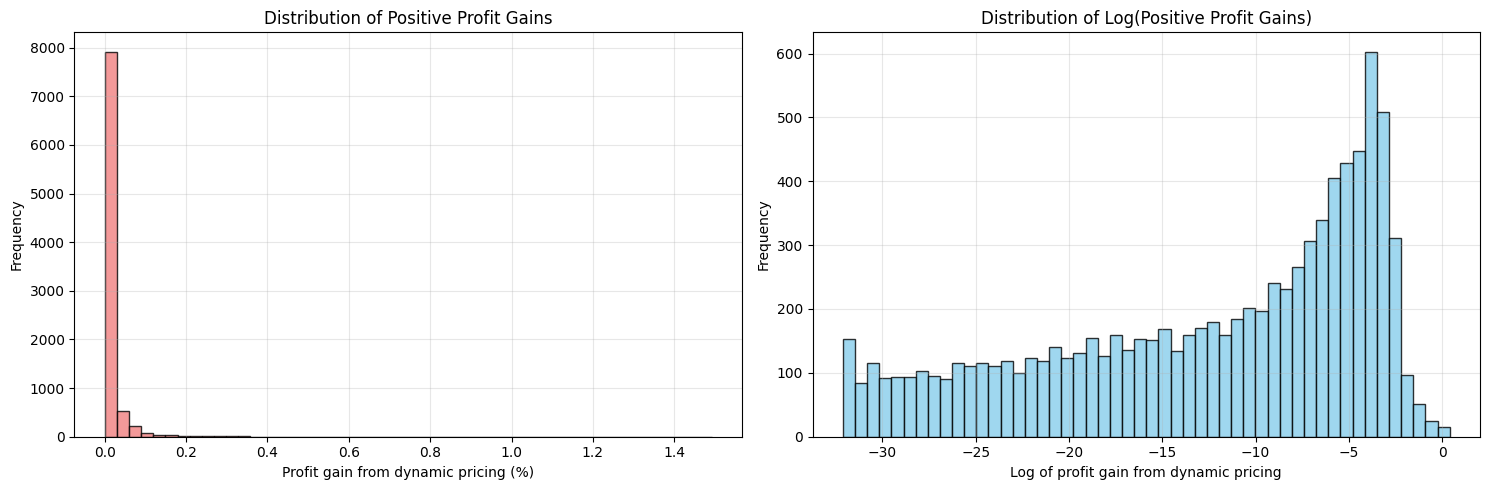

In [20]:
import matplotlib.pyplot as plt
import numpy as np

# Filter for positive gains
positive_gains = lhs_df[lhs_df['gain_pct'] > 0]['gain_pct']
log_positive_gains = np.log(positive_gains)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Subplot 1: Raw Positive Gains
axes[0].hist(positive_gains, bins=50, color='lightcoral', edgecolor='black', alpha=0.8)
axes[0].set_xlabel('Profit gain from dynamic pricing (%)')
axes[0].set_ylabel('Frequency')
axes[0].set_title('Distribution of Positive Profit Gains')
axes[0].grid(True, alpha=0.3)

# Subplot 2: Log-transformed Positive Gains
axes[1].hist(log_positive_gains, bins=50, color='skyblue', edgecolor='black', alpha=0.8)
axes[1].set_xlabel('Log of profit gain from dynamic pricing')
axes[1].set_ylabel('Frequency')
axes[1].set_title('Distribution of Log(Positive Profit Gains)')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

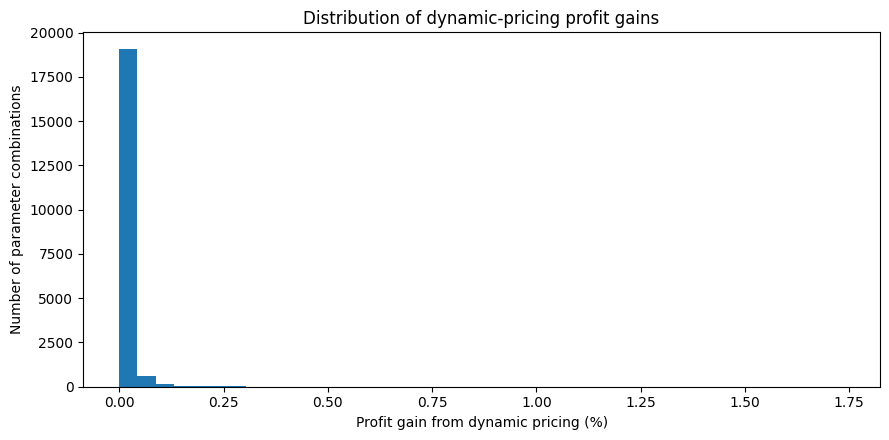

Top 1.0% gain threshold: 0.1230%
Number of high-gain observations: 200 / 20000


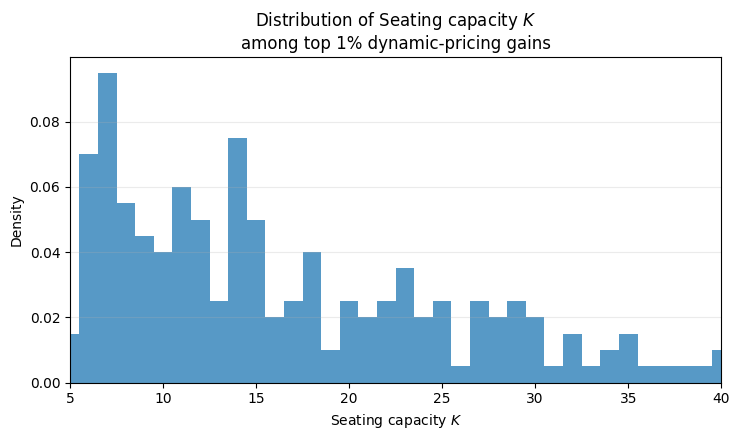

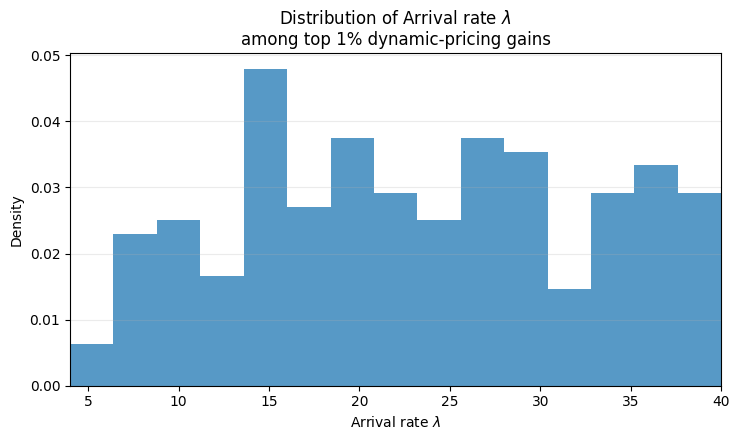

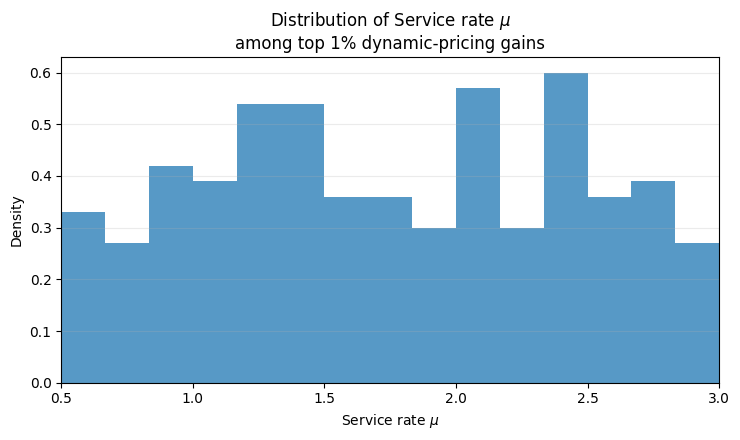

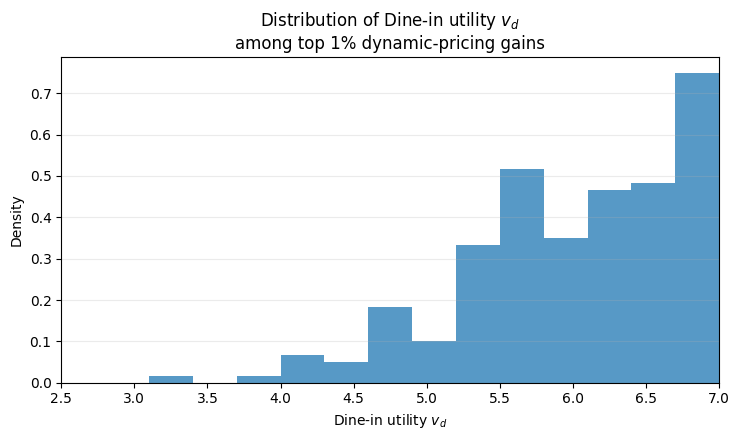

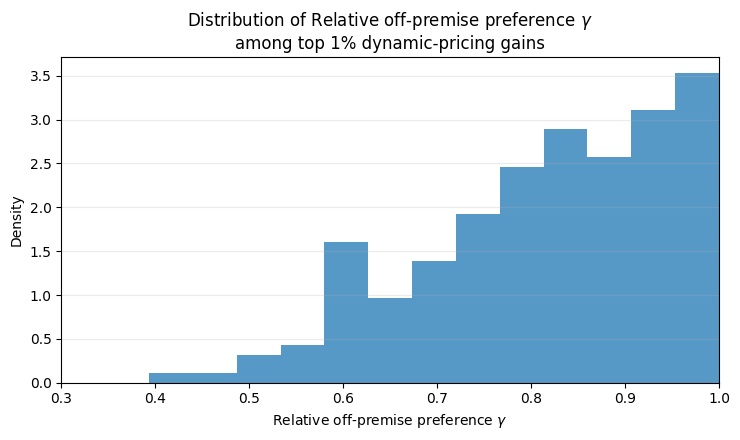

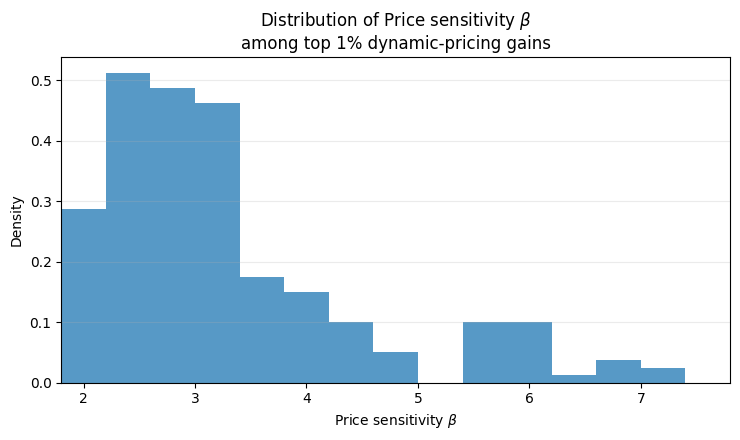

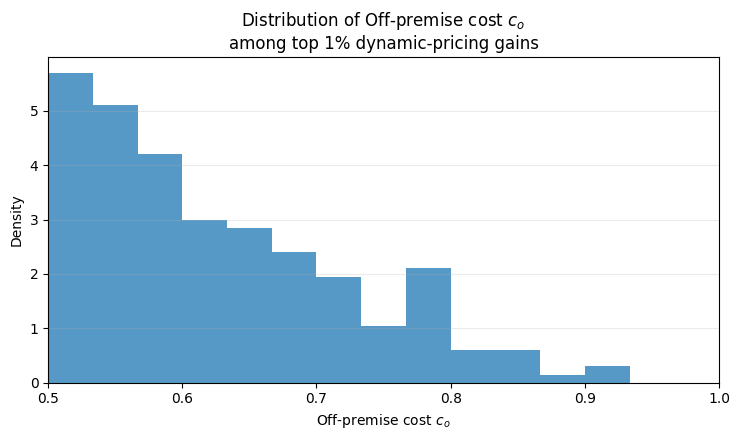

In [4]:
high_gain_df, gain_threshold = (
    plot_high_gain_parameter_distributions(
        lhs_df,
        search_space=SEARCH_SPACE,
        top_percent=1
    )
)

In [ ]:
high_gain_df, gain_threshold = (
    plot_high_gain_parameter_distributions(
        lhs_df,
        search_space=SEARCH_SPACE,
        top_percent=1
    )
)

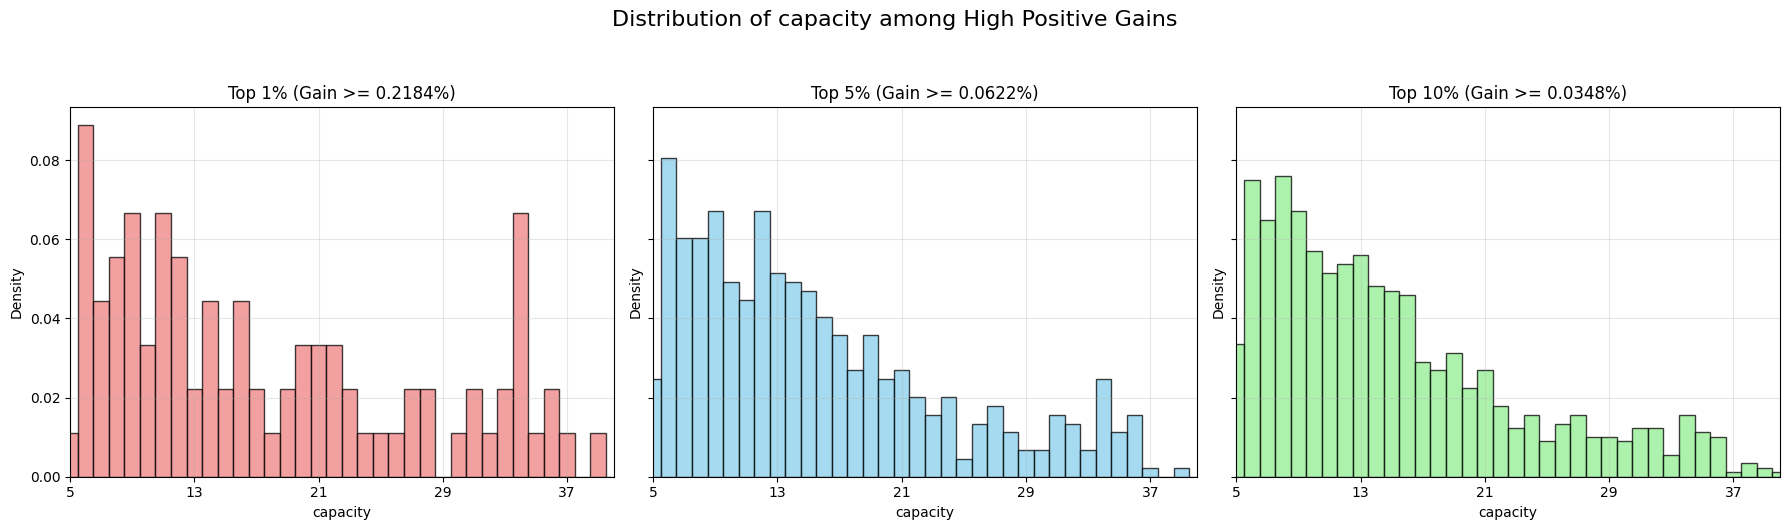

Saved: positive_gain_top_distributions_capacity.pdf


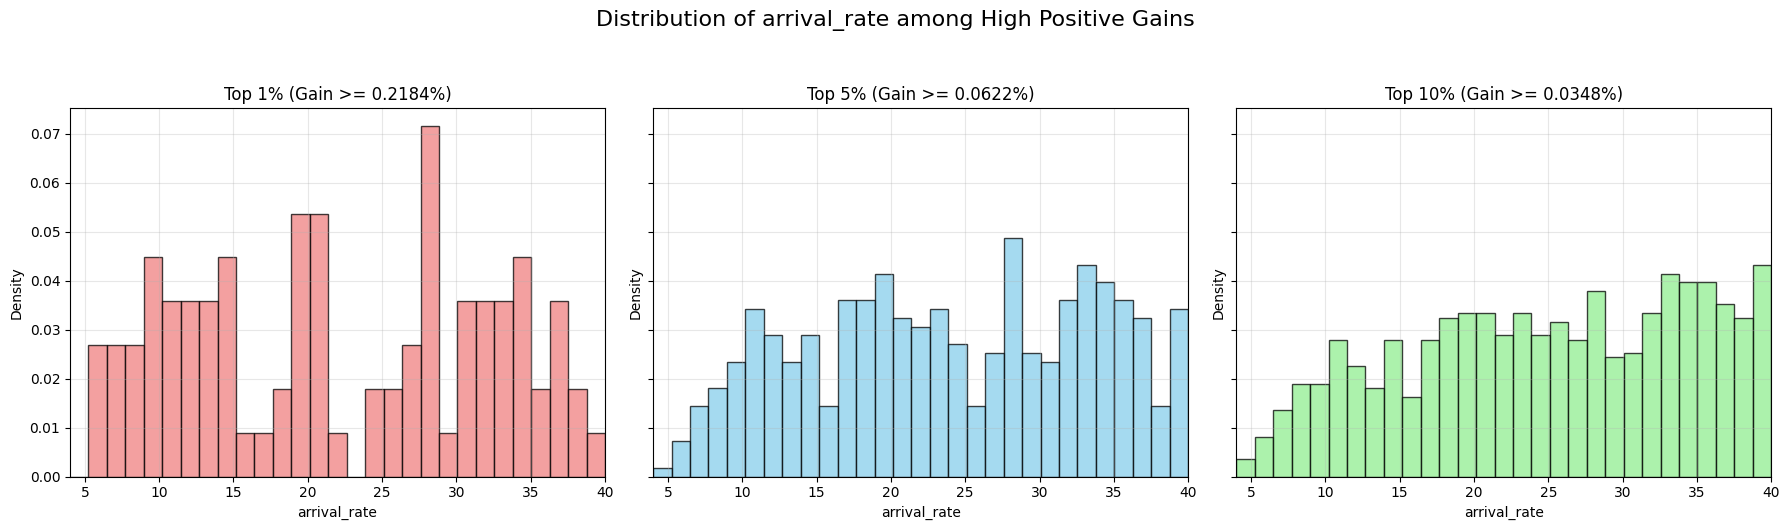

Saved: positive_gain_top_distributions_arrival_rate.pdf


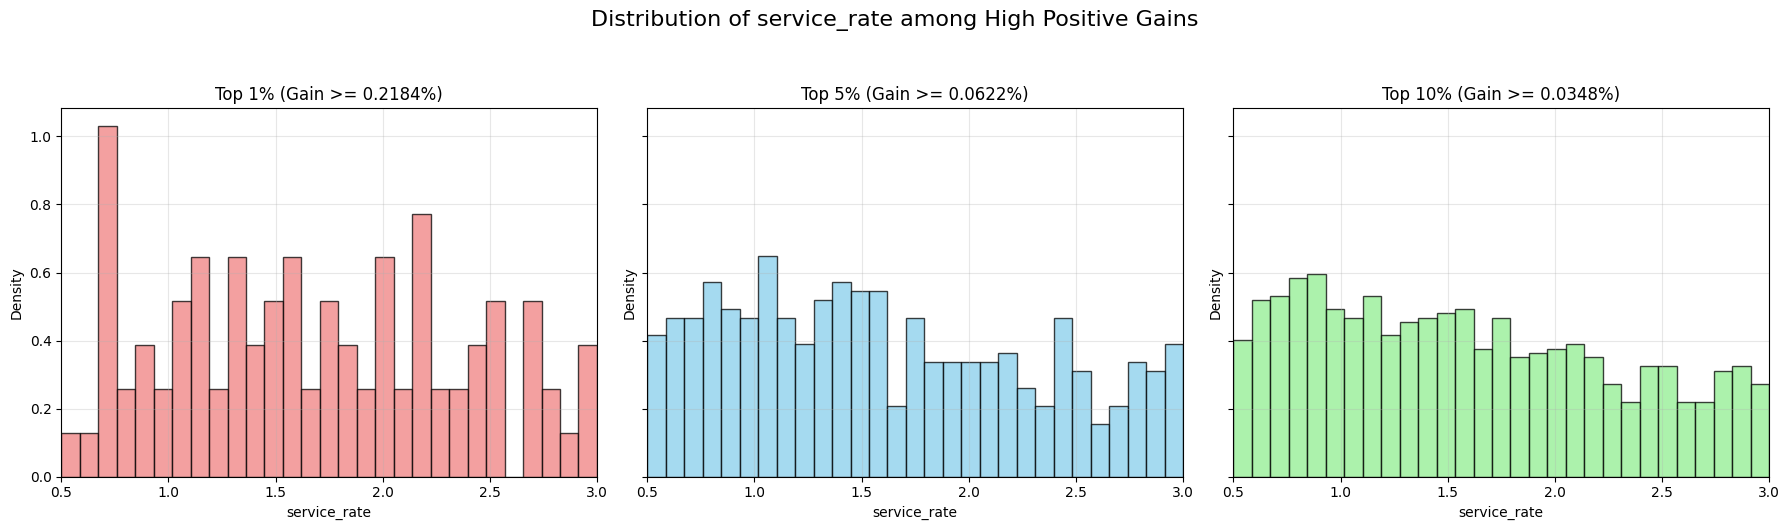

Saved: positive_gain_top_distributions_service_rate.pdf


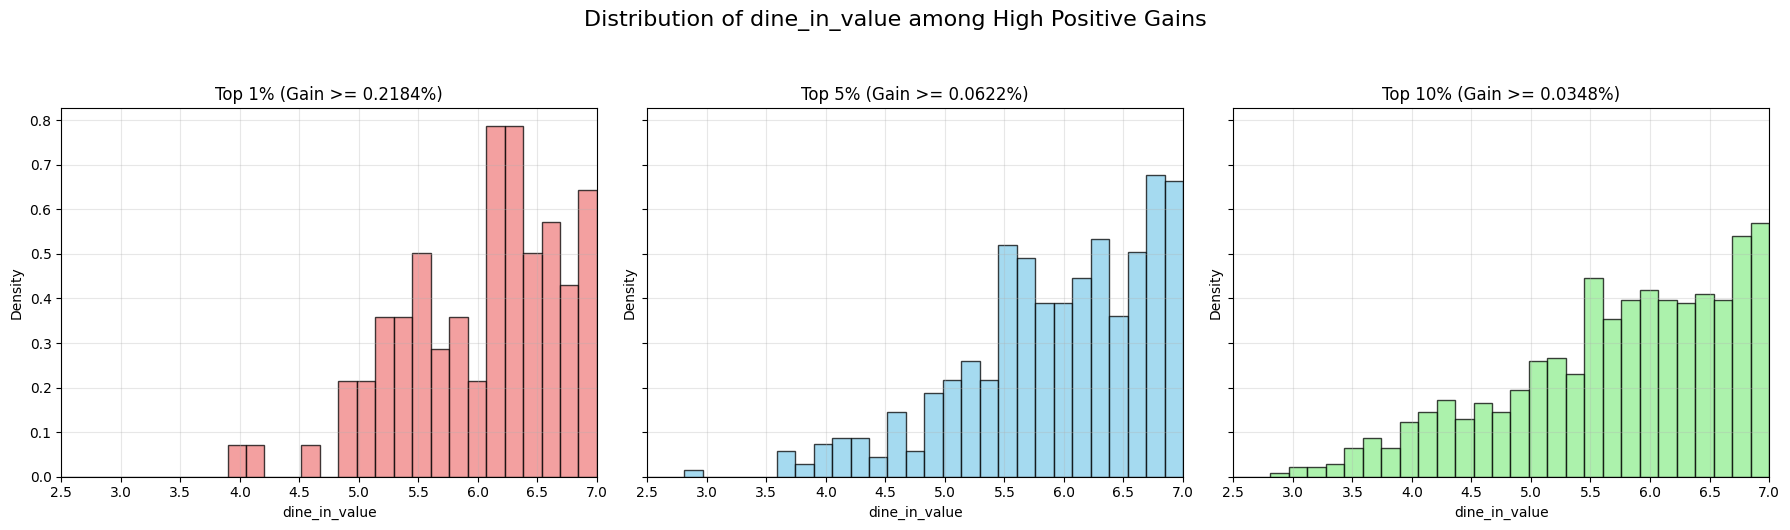

Saved: positive_gain_top_distributions_dine_in_value.pdf


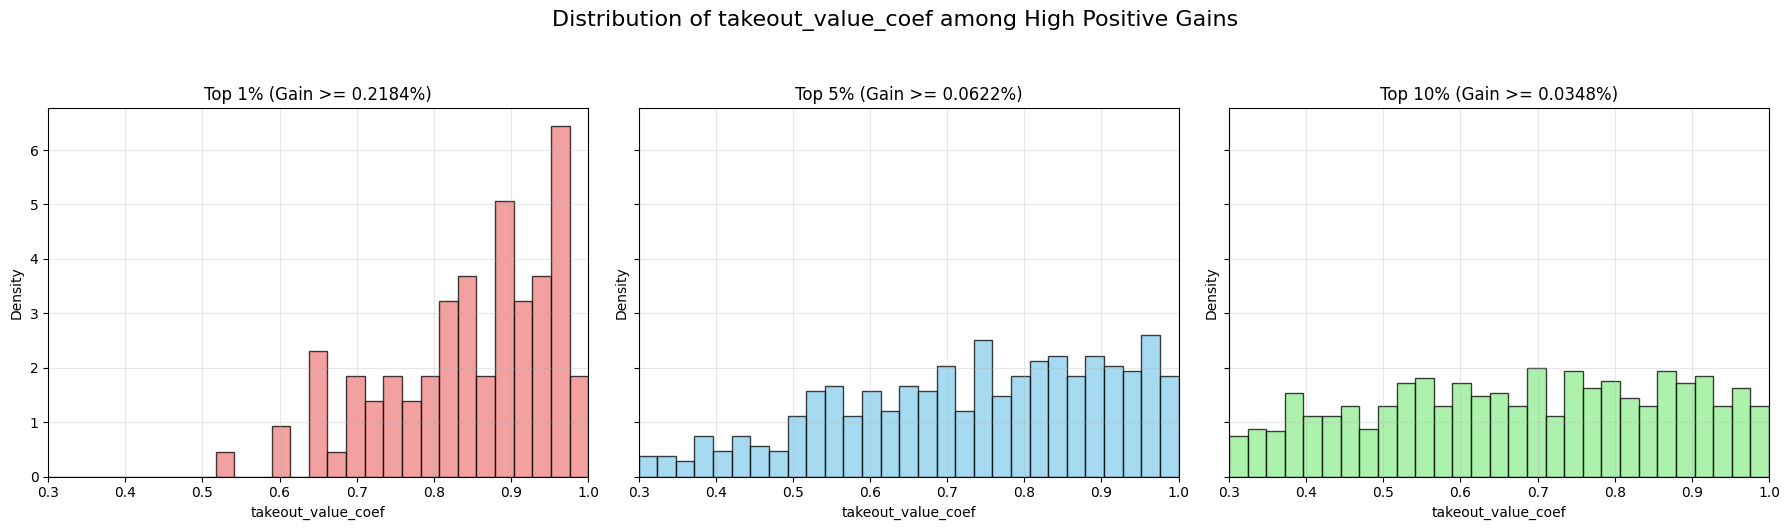

Saved: positive_gain_top_distributions_takeout_value_coef.pdf


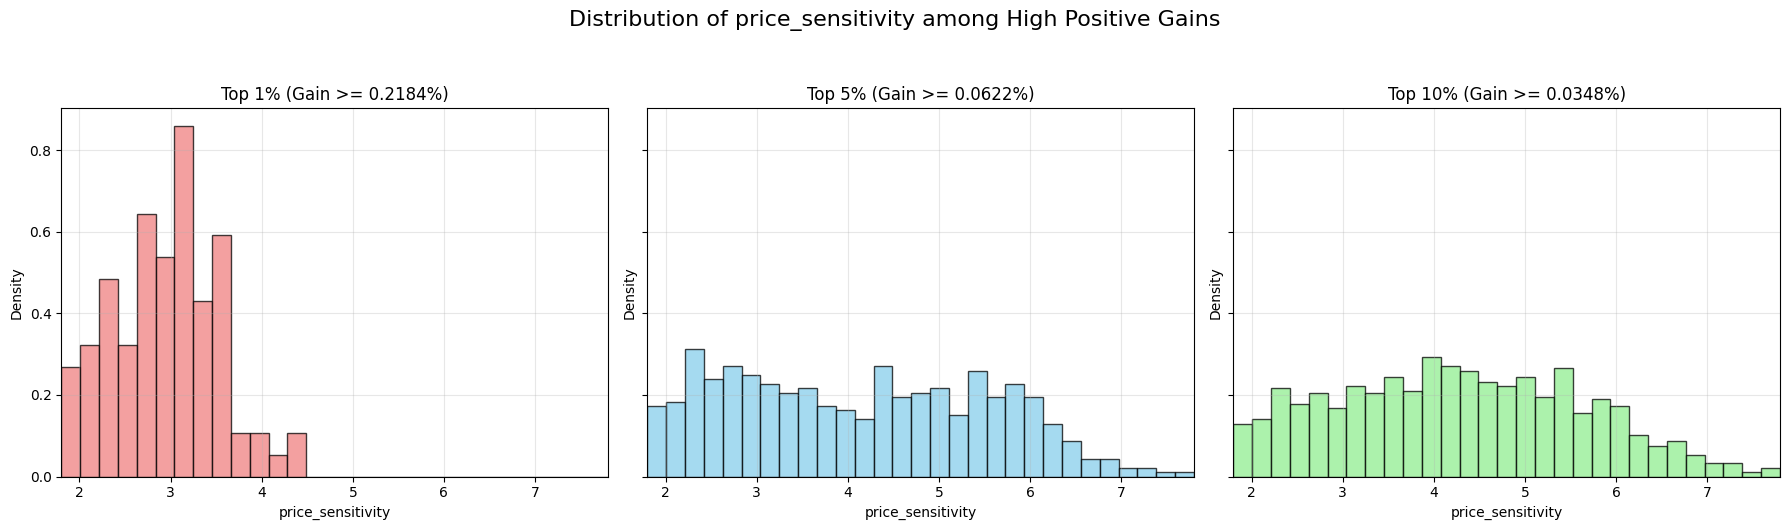

Saved: positive_gain_top_distributions_price_sensitivity.pdf


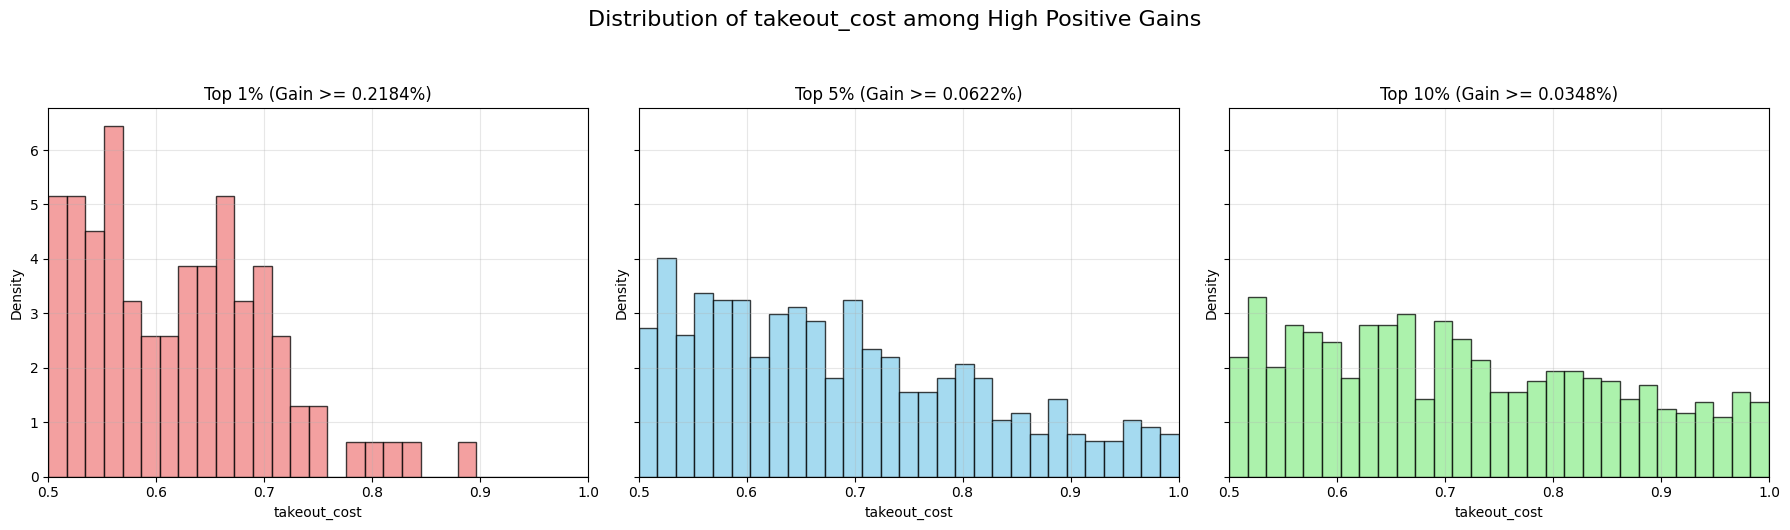

Saved: positive_gain_top_distributions_takeout_cost.pdf


In [15]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 1. Restrict to positive gain only
positive_gain_df = lhs_df[lhs_df['gain_pct'] > 0].copy()

# 2. Determine thresholds for top 1%, 5%, and 10% within the positive gain subset
threshold_1 = positive_gain_df['gain_pct'].quantile(0.99)
threshold_5 = positive_gain_df['gain_pct'].quantile(0.95)
threshold_10 = positive_gain_df['gain_pct'].quantile(0.90)

thresholds = [threshold_1, threshold_5, threshold_10]
labels = ['Top 1%', 'Top 5%', 'Top 10%']
colors = ['lightcoral', 'skyblue', 'lightgreen']

# 3. Parameters to plot
parameters = list(SEARCH_SPACE.keys())

for param_name in parameters:
    lower_bound, upper_bound = SEARCH_SPACE[param_name]

    # Determine consistent binning strategy
    if param_name == 'capacity':
        bin_edges = np.arange(int(lower_bound) - 0.5, int(upper_bound) + 1.5, 1)
        x_ticks = np.arange(int(lower_bound), int(upper_bound) + 1, (int(upper_bound) - int(lower_bound)) // 5 + 1)
    else:
        bin_edges = np.linspace(lower_bound, upper_bound, 30)
        x_ticks = None

    fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
    fig.suptitle(f'Distribution of {param_name} among High Positive Gains', fontsize=16, y=1.05)

    for i, (thresh, label, color) in enumerate(zip(thresholds, labels, colors)):
        # Filter data to the specific threshold
        subset_df = positive_gain_df[positive_gain_df['gain_pct'] >= thresh]

        axes[i].hist(
            subset_df[param_name],
            bins=bin_edges,
            density=True,
            alpha=0.75,
            color=color,
            edgecolor='black'
        )
        axes[i].set_title(f'{label} (Gain >= {thresh:.4f}%)')
        axes[i].set_xlabel(param_name)
        axes[i].set_ylabel('Density')
        axes[i].set_xlim(lower_bound, upper_bound)
        if x_ticks is not None:
            axes[i].set_xticks(x_ticks)
        axes[i].grid(True, alpha=0.3)

    plt.tight_layout()
    save_name = f"positive_gain_top_distributions_{param_name}.pdf"
    plt.savefig(save_name, bbox_inches='tight')
    plt.show()
    print(f"Saved: {save_name}")

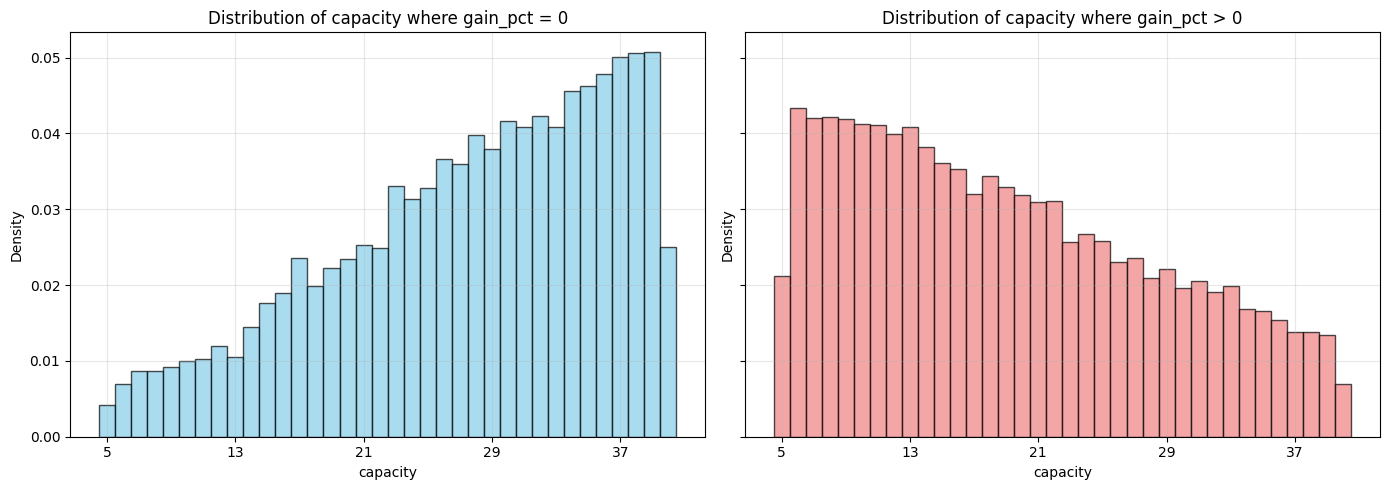

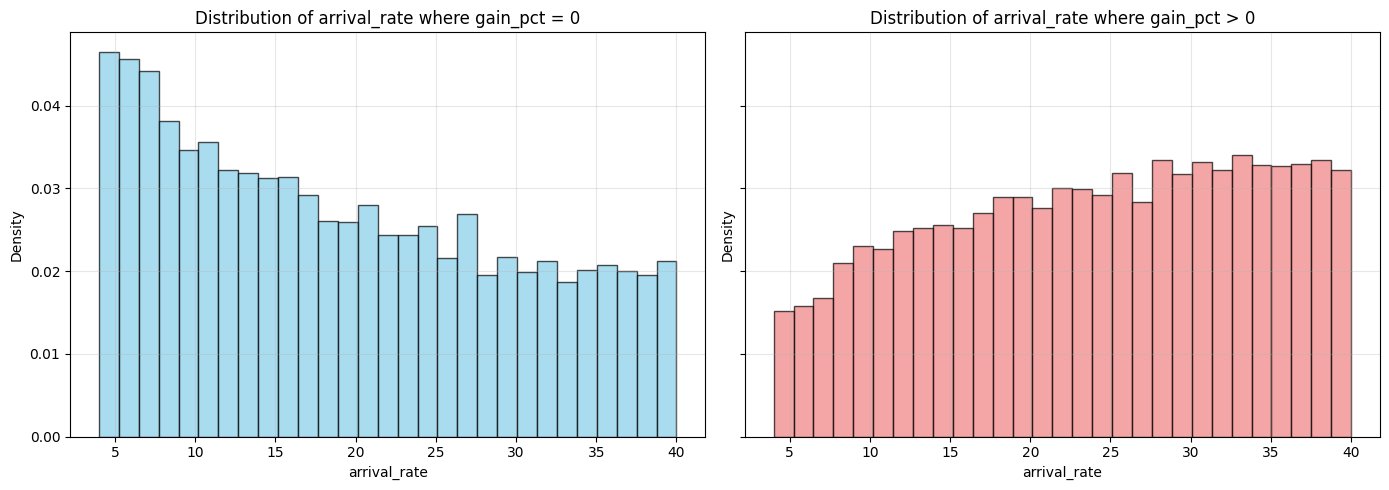

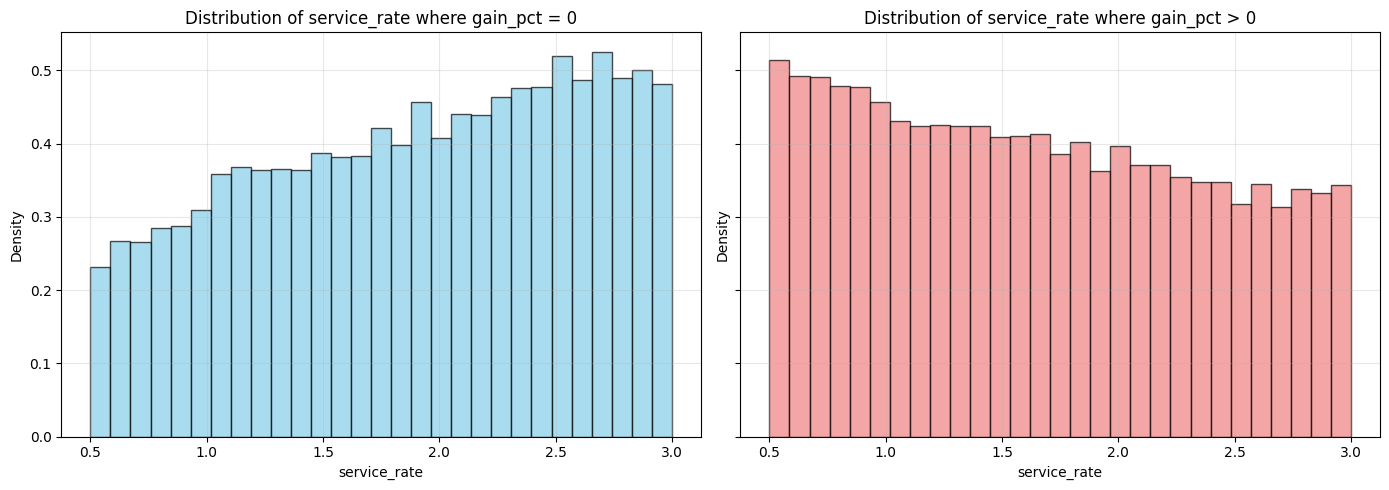

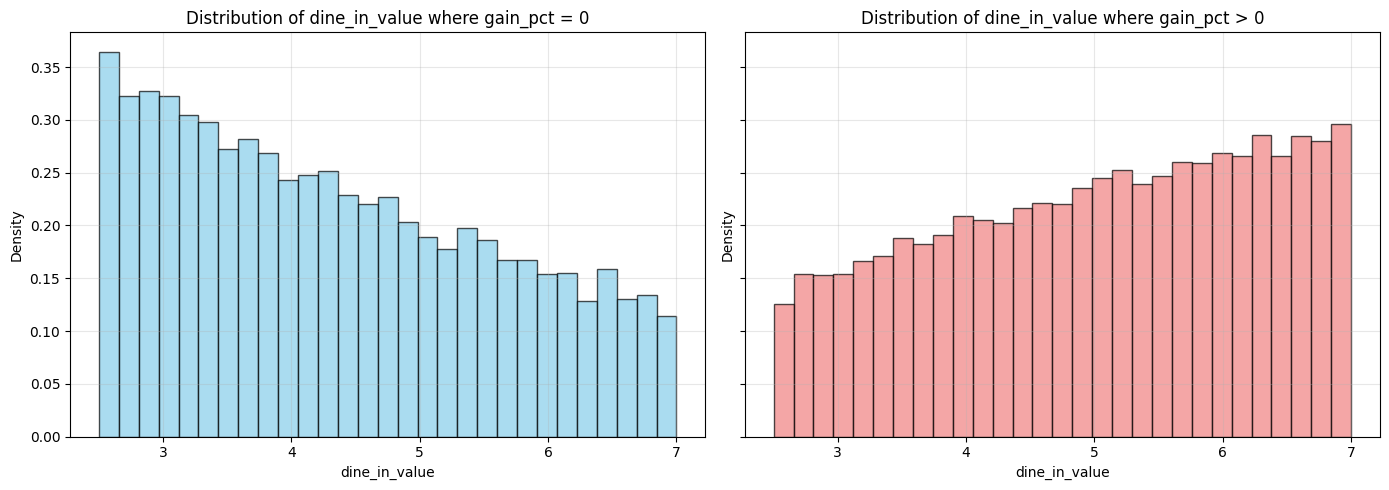

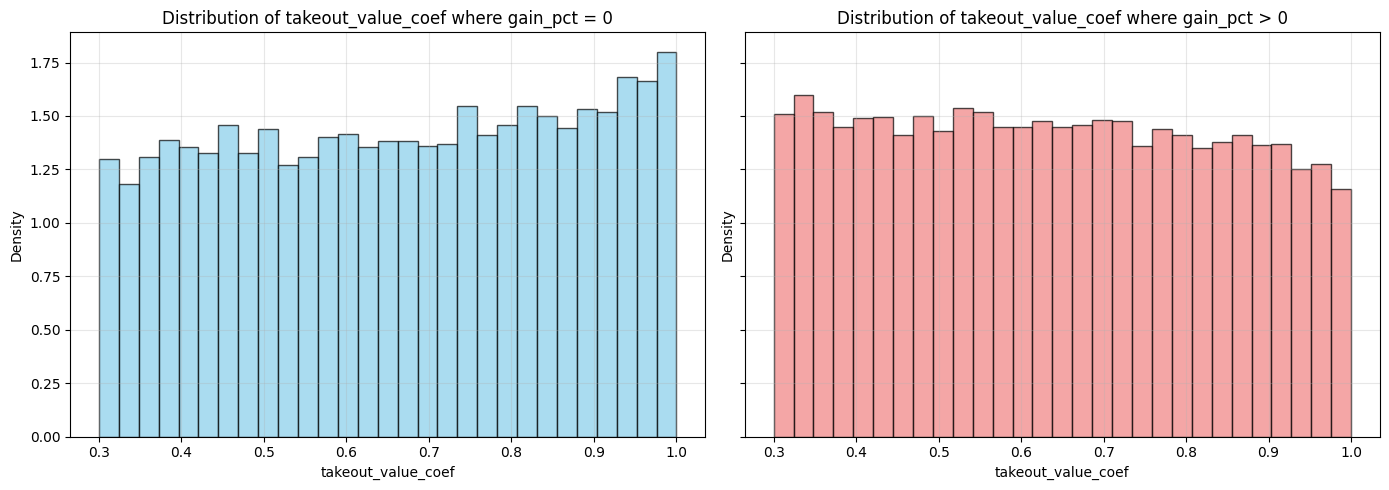

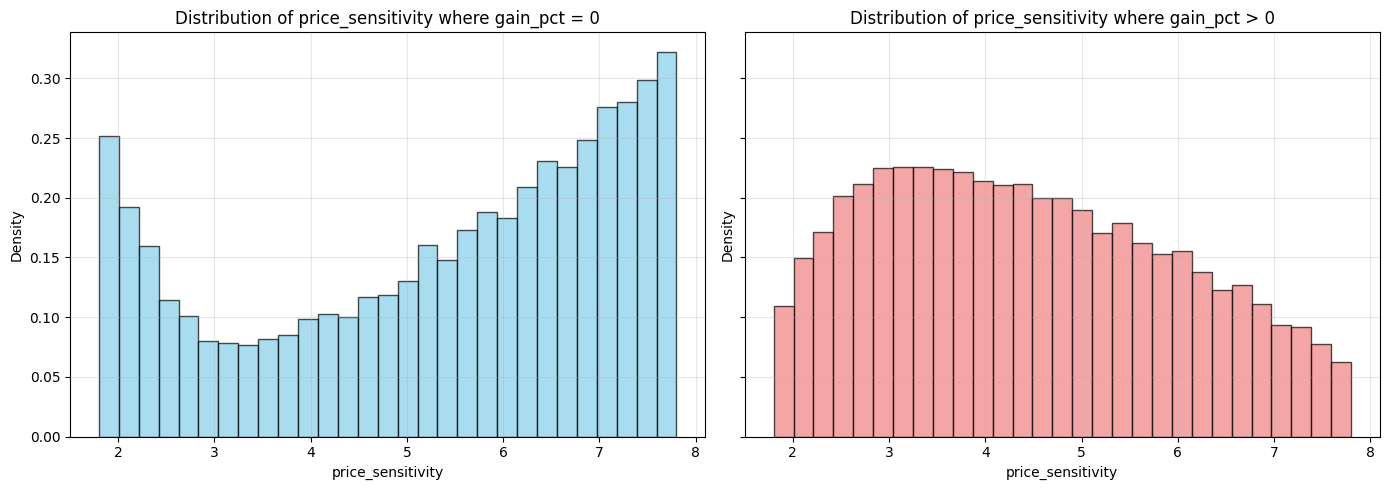

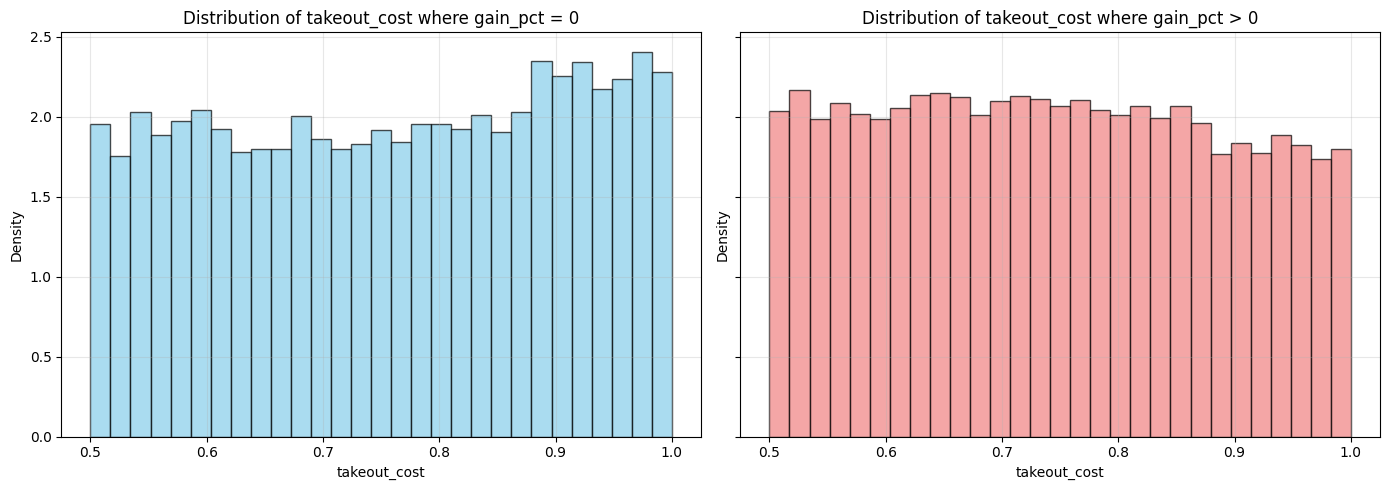

In [16]:
import matplotlib.pyplot as plt
import numpy as np

# Define the parameters to iterate through
parameters_to_plot = SEARCH_SPACE.keys()

for param_name in parameters_to_plot:
    # Filter data for gain_pct == 0 and gain_pct > 0
    param_zero_gain = lhs_df[lhs_df['gain_pct'] == 0][param_name]
    param_positive_gain = lhs_df[lhs_df['gain_pct'] > 0][param_name]

    # Determine bin edges from SEARCH_SPACE, handling capacity specifically
    lower_bound, upper_bound = SEARCH_SPACE[param_name]

    if param_name == 'capacity':
        bin_edges = np.arange(int(lower_bound) - 0.5, int(upper_bound) + 1.5, 1)
        x_ticks = np.arange(int(lower_bound), int(upper_bound) + 1, (int(upper_bound) - int(lower_bound)) // 5 + 1)
    else:
        bin_edges = np.linspace(lower_bound, upper_bound, 30)
        x_ticks = None # Let matplotlib decide for continuous vars

    fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

    # Plot for gain_pct == 0
    axes[0].hist(
        param_zero_gain,
        bins=bin_edges,
        density=True,
        alpha=0.7,
        color='skyblue',
        edgecolor='black'
    )
    axes[0].set_title(f'Distribution of {param_name} where gain_pct = 0')
    axes[0].set_xlabel(param_name)
    axes[0].set_ylabel('Density')
    if x_ticks is not None: axes[0].set_xticks(x_ticks)
    axes[0].grid(True, alpha=0.3)

    # Plot for gain_pct > 0
    axes[1].hist(
        param_positive_gain,
        bins=bin_edges,
        density=True,
        alpha=0.7,
        color='lightcoral',
        edgecolor='black'
    )
    axes[1].set_title(f'Distribution of {param_name} where gain_pct > 0')
    axes[1].set_xlabel(param_name)
    axes[1].set_ylabel('Density')
    if x_ticks is not None: axes[1].set_xticks(x_ticks)
    axes[1].grid(True, alpha=0.3)

    plt.tight_layout()

    plt.savefig(f"positive_zero_gain_{param_name}_distribution.pdf")
    plt.show()

## Step 4: neural-network surrogate

In [6]:
hurdle_result = train_hurdle_nn_surrogate(
    lhs_df,
    target="gain_pct",
    zero_tolerance=1e-10,
    test_size=0.20,
    seed=None
)

STAGE 1: Positive-gain classification
Positive rate in full data: 0.4967
Accuracy: 0.9690
ROC AUC: 0.9939
Log loss: 0.0927

STAGE 2: Positive-gain regression
Positive observations in test set: 1490
R²: 0.7395
RMSE: 0.0313
MAE: 0.0072

COMBINED HURDLE MODEL
Overall R²: 0.7550
Overall RMSE: 0.0218
Overall MAE: 0.0036


In [17]:
# (
#     nn_model,
#     X_train,
#     X_test,
#     y_train,
#     y_test,
#     predictions
# ) = train_nn_surrogate(
#     lhs_df,
#     seed = None
# )

Target = gain_pct
Test R² = 0.8360
Test RMSE = 0.0208


### get feature importance.

            parameter  importance       std
0   price_sensitivity    1.184045  0.170760
1            capacity    1.104825  0.138239
2       dine_in_value    1.014010  0.179700
3        arrival_rate    0.955657  0.174494
4        service_rate    0.791129  0.096258
5        takeout_cost    0.709271  0.147088
6  takeout_value_coef    0.689330  0.136260


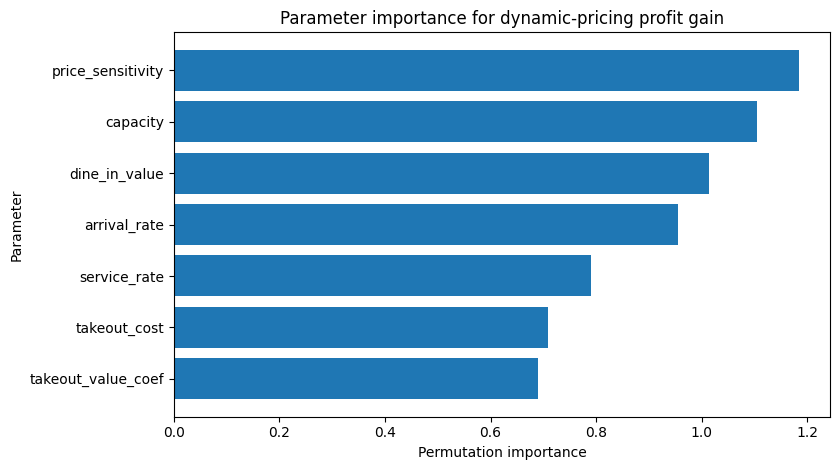

In [6]:
importance_df = (
    calculate_permutation_importance(
        nn_model,
        X_test,
        y_test,
        n_repeats=30
    )
)

print(importance_df)

plot_permutation_importance(
    importance_df
)

### get shapley value

#### get shapley value for classficiation

In [7]:
import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def calculate_classifier_shap(
    hurdle_result,
    background_size=200,
    explanation_size=500,
    seed=123
):
    """
    Calculate SHAP values for Stage 1 of the hurdle model:

        P(gain_pct > 0 | X)

    SHAP values therefore explain changes in the predicted
    probability that dynamic pricing generates positive profit gain.

    Returns
    -------
    shap_values : shap.Explanation
    shap_df : DataFrame
        Observation-level SHAP values.
    global_shap_df : DataFrame
        Mean absolute SHAP importance for each parameter.
    X_explain : DataFrame
        Feature values corresponding to the SHAP observations.
    """

    classifier = hurdle_result["classifier"]

    X_train = hurdle_result["X_train"]
    X_test = hurdle_result["X_test"]

    feature_names = list(X_train.columns)

    # --------------------------------------------------------
    # Background observations
    # --------------------------------------------------------

    n_background = min(
        background_size,
        len(X_train)
    )

    background = X_train.sample(
        n=n_background,
        random_state=seed
    )

    # --------------------------------------------------------
    # Test observations to explain
    # --------------------------------------------------------

    n_explain = min(
        explanation_size,
        len(X_test)
    )

    X_explain = X_test.sample(
        n=n_explain,
        random_state=seed
    )

    # --------------------------------------------------------
    # Wrapper:
    # return probability of positive gain
    # --------------------------------------------------------

    def predict_positive_probability(X):

        # SHAP may pass an ndarray instead of DataFrame
        if not isinstance(X, pd.DataFrame):

            X = pd.DataFrame(
                X,
                columns=feature_names
            )

        return classifier.predict_proba(X)[:, 1]

    # --------------------------------------------------------
    # SHAP explainer
    # --------------------------------------------------------

    explainer = shap.Explainer(
        predict_positive_probability,
        background,
        algorithm="permutation"
    )

    shap_values = explainer(
        X_explain
    )

    # --------------------------------------------------------
    # Observation-level values
    # --------------------------------------------------------

    shap_df = pd.DataFrame(
        shap_values.values,
        columns=feature_names,
        index=X_explain.index
    )

    # --------------------------------------------------------
    # Global importance
    # --------------------------------------------------------

    global_shap_df = pd.DataFrame({

        "parameter":
            feature_names,

        "mean_abs_shap":
            np.abs(
                shap_values.values
            ).mean(axis=0),

        "mean_shap":
            shap_values.values.mean(
                axis=0
            )
    })

    global_shap_df = (
        global_shap_df
        .sort_values(
            "mean_abs_shap",
            ascending=False
        )
        .reset_index(drop=True)
    )

    return (
        shap_values,
        shap_df,
        global_shap_df,
        X_explain
    )

In [8]:
(
    classifier_shap_values,
    classifier_shap_df,
    classifier_global_shap,
    X_classifier_shap
) = calculate_classifier_shap(
    hurdle_result,
    background_size=200,
    explanation_size=500,
    seed=None
)

print(classifier_global_shap)

classifier.predict_proba(X)[:, 1]

PermutationExplainer explainer: 501it [02:45,  3.01it/s]

            parameter  mean_abs_shap  mean_shap
0            capacity       0.205272   0.008284
1   price_sensitivity       0.170096   0.024514
2       dine_in_value       0.117015  -0.015287
3        arrival_rate       0.104695  -0.005442
4        service_rate       0.086496   0.008195
5        takeout_cost       0.045239   0.007494
6  takeout_value_coef       0.029561   0.004290


NameError: name 'classifier' is not defined

#### get shapley value for regression

In [9]:
def calculate_positive_regression_shap(
    hurdle_result,
    background_size=200,
    explanation_size=500,
    seed=123
):
    """
    Calculate SHAP values for Stage 2 of the hurdle model:

        E[gain_pct | gain_pct > 0, X]

    The regression model was trained on log1p(gain_pct), but
    the prediction wrapper converts predictions back using expm1().

    Therefore, SHAP explains conditional gain on the original
    gain_pct scale.

    Returns
    -------
    shap_values : shap.Explanation

    shap_df : DataFrame
        Observation-level SHAP values.

    global_shap_df : DataFrame
        Global importance based on mean absolute SHAP.

    X_explain : DataFrame
        Positive-gain observations used for explanation.
    """

    regressor = hurdle_result[
        "positive_regressor"
    ]

    X_train = hurdle_result[
        "X_train"
    ]

    X_test = hurdle_result[
        "X_test"
    ]

    y_train = hurdle_result[
        "y_train"
    ]

    y_test = hurdle_result[
        "y_test"
    ]

    feature_names = list(
        X_train.columns
    )

    # --------------------------------------------------------
    # Restrict background to positive-gain observations
    # --------------------------------------------------------

    positive_train_mask = (
        y_train > 1e-10
    )

    X_train_positive = X_train.loc[
        positive_train_mask
    ]

    # --------------------------------------------------------
    # Explain positive test observations only
    # --------------------------------------------------------

    positive_test_mask = (
        y_test > 1e-10
    )

    X_test_positive = X_test.loc[
        positive_test_mask
    ]

    # --------------------------------------------------------
    # Background sample
    # --------------------------------------------------------

    n_background = min(
        background_size,
        len(X_train_positive)
    )

    background = (
        X_train_positive.sample(
            n=n_background,
            random_state=seed
        )
    )

    # --------------------------------------------------------
    # Explanation sample
    # --------------------------------------------------------

    n_explain = min(
        explanation_size,
        len(X_test_positive)
    )

    X_explain = (
        X_test_positive.sample(
            n=n_explain,
            random_state=seed
        )
    )

    # --------------------------------------------------------
    # Wrapper:
    #
    # original regressor predicts log(1 + gain_pct)
    #
    # Convert prediction back to gain_pct.
    # --------------------------------------------------------

    def predict_positive_gain(X):

        if not isinstance(
            X,
            pd.DataFrame
        ):

            X = pd.DataFrame(
                X,
                columns=feature_names
            )

        log_prediction = (
            regressor.predict(X)
        )

        prediction = np.expm1(
            log_prediction
        )

        # Prevent numerical negative values
        prediction = np.maximum(
            prediction,
            0.0
        )

        return prediction

    # --------------------------------------------------------
    # SHAP explainer
    # --------------------------------------------------------

    explainer = shap.Explainer(
        predict_positive_gain,
        background,
        algorithm="permutation"
    )

    shap_values = explainer(
        X_explain
    )

    # --------------------------------------------------------
    # Observation-level SHAP values
    # --------------------------------------------------------

    shap_df = pd.DataFrame(
        shap_values.values,
        columns=feature_names,
        index=X_explain.index
    )

    # --------------------------------------------------------
    # Global SHAP importance
    # --------------------------------------------------------

    global_shap_df = pd.DataFrame({

        "parameter":
            feature_names,

        "mean_abs_shap":
            np.abs(
                shap_values.values
            ).mean(axis=0),

        "mean_shap":
            shap_values.values.mean(
                axis=0
            )
    })

    global_shap_df = (
        global_shap_df
        .sort_values(
            "mean_abs_shap",
            ascending=False
        )
        .reset_index(drop=True)
    )

    return (
        shap_values,
        shap_df,
        global_shap_df,
        X_explain
    )

In [10]:
(
    regression_shap_values,
    regression_shap_df,
    regression_global_shap,
    X_regression_shap
) = calculate_positive_regression_shap(
    hurdle_result,
    background_size=200,
    explanation_size=500,
    seed=None
)

print(regression_global_shap)

PermutationExplainer explainer: 501it [02:44,  2.95it/s]

            parameter  mean_abs_shap  mean_shap
0       dine_in_value       0.009891   0.001104
1            capacity       0.007975   0.002627
2   price_sensitivity       0.006480   0.000399
3  takeout_value_coef       0.005744  -0.000213
4        service_rate       0.004917   0.000516
5        arrival_rate       0.004723   0.000217
6        takeout_cost       0.004223  -0.000699


#### plot

Saved to: SHAP_classifier_importance.pdf


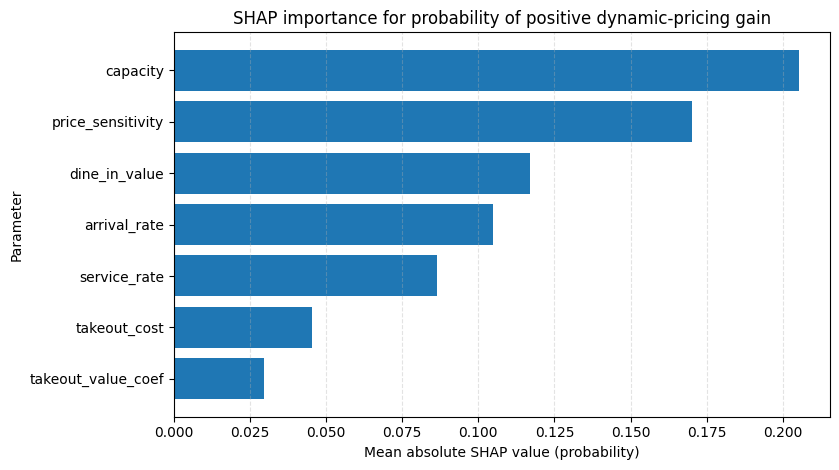

Saved to: SHAP_regression_importance.pdf


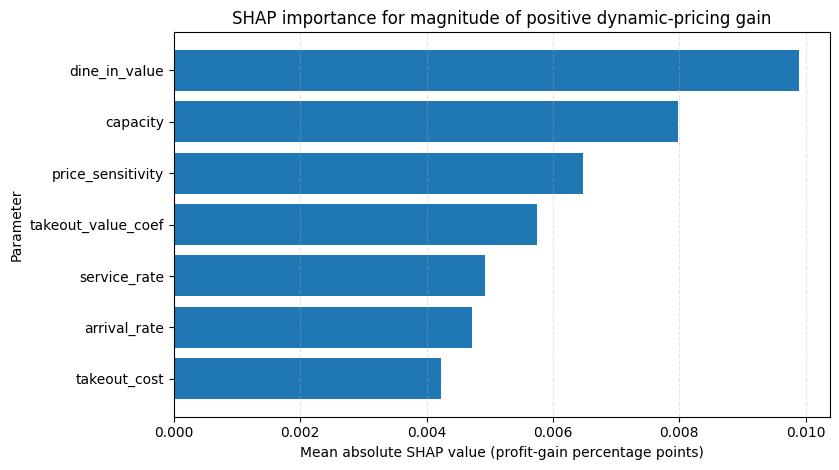

In [13]:
def plot_global_shap_importance(
    global_shap_df,
    title,
    xlabel,
    save_path=None,
    dpi=300
):

    df = global_shap_df.sort_values(
        "mean_abs_shap",
        ascending=True
    )

    fig, ax = plt.subplots(
        figsize=(8.5, 4.8)
    )

    ax.barh(
        df["parameter"],
        df["mean_abs_shap"]
    )

    ax.set_xlabel(
        xlabel
    )

    ax.set_ylabel(
        "Parameter"
    )

    ax.set_title(
        title
    )

    ax.grid(
        True,
        axis="x",
        linestyle="--",
        alpha=0.35
    )

    plt.tight_layout()

    if save_path is not None:

        fig.savefig(
            save_path,
            dpi=dpi,
            bbox_inches="tight"
        )

        print(
            f"Saved to: {save_path}"
        )

    plt.show()


plot_global_shap_importance(
  classifier_global_shap,

  title=(
      "SHAP importance for probability "
      "of positive dynamic-pricing gain"
  ),

  xlabel=(
      "Mean absolute SHAP value "
      "(probability)"
  ),

  save_path="SHAP_classifier_importance.pdf"
)

plot_global_shap_importance(
  regression_global_shap,

  title=(
      "SHAP importance for magnitude "
      "of positive dynamic-pricing gain"
  ),

  xlabel=(
      "Mean absolute SHAP value "
      "(profit-gain percentage points)"
  ),

  save_path="SHAP_regression_importance.pdf"
)

NameError: name 'plot_global_shap_importance' is not defined

### plot the partial dependence.

Figure saved to: PDP_positive_gain_capacity.pdf


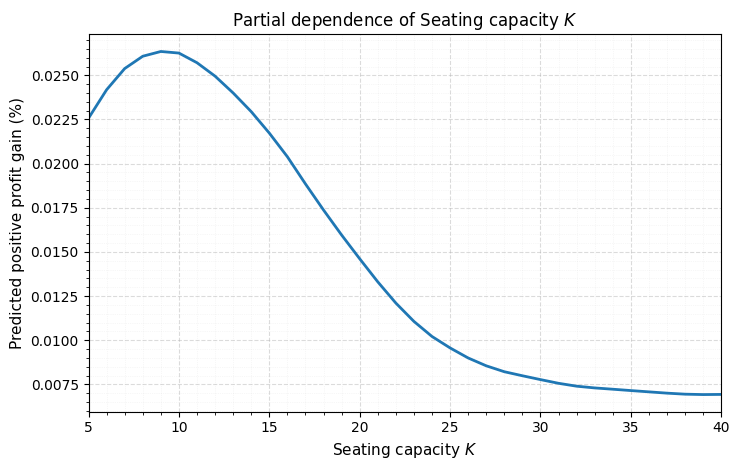

Figure saved to: PDP_positive_gain_arrival_rate.pdf


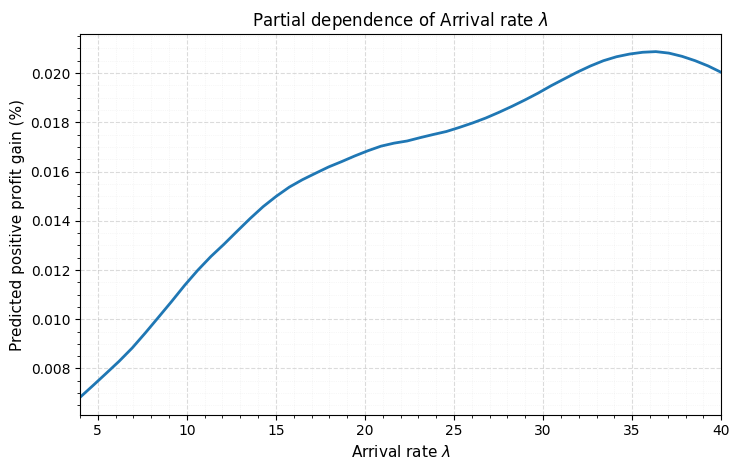

Figure saved to: PDP_positive_gain_service_rate.pdf


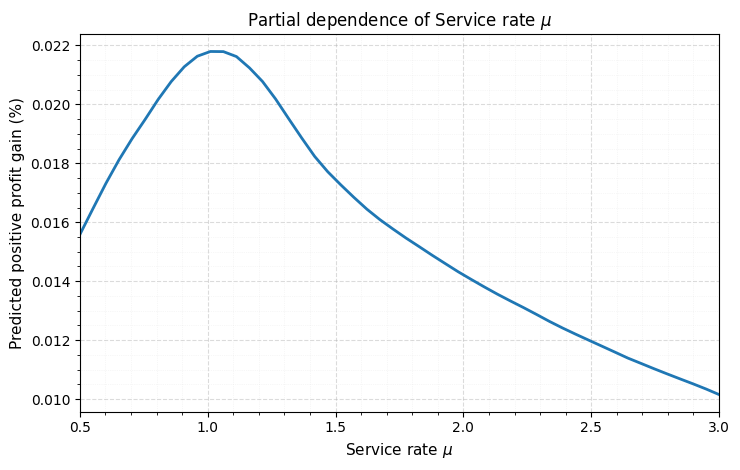

Figure saved to: PDP_positive_gain_dine_in_value.pdf


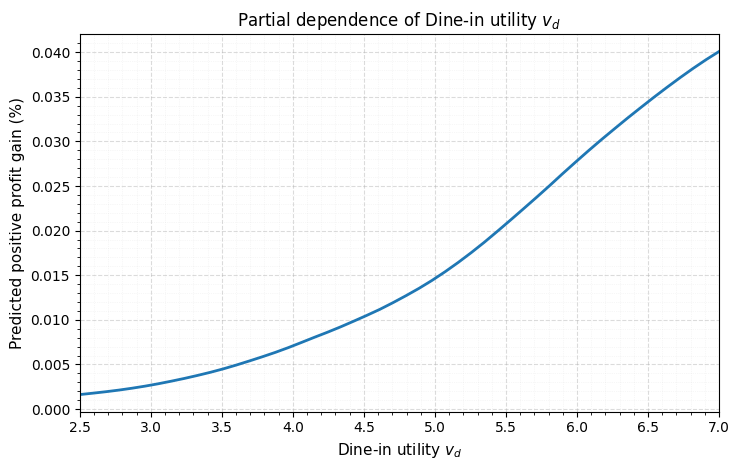

Figure saved to: PDP_positive_gain_takeout_value_coef.pdf


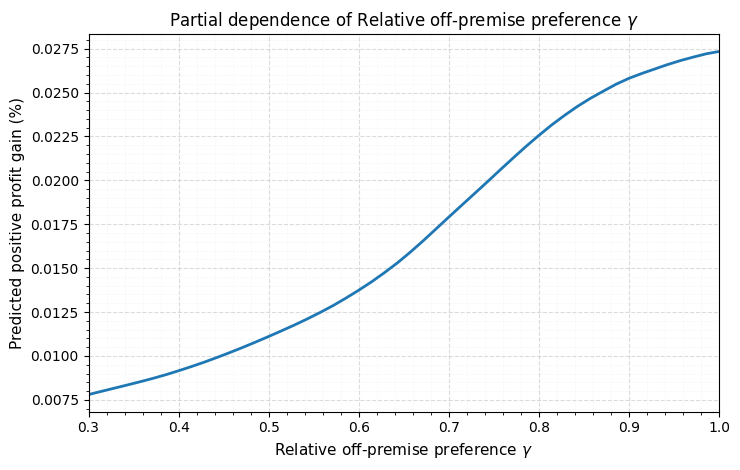

Figure saved to: PDP_positive_gain_price_sensitivity.pdf


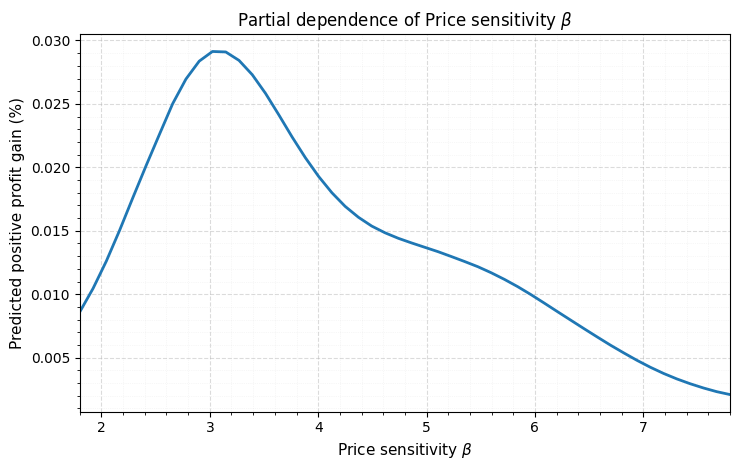

Figure saved to: PDP_positive_gain_takeout_cost.pdf


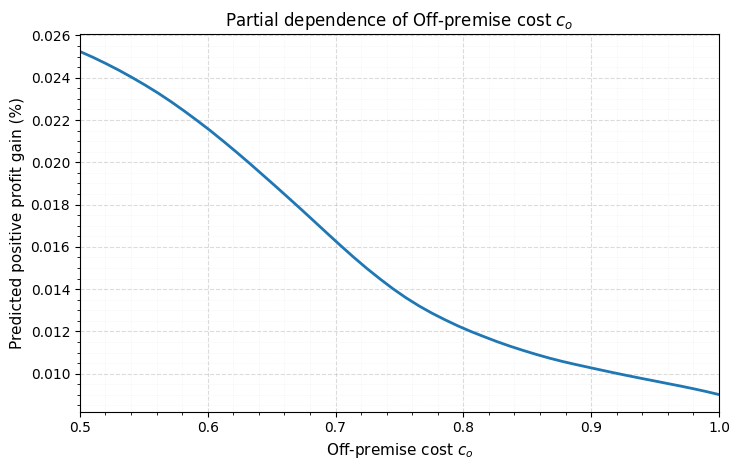

In [17]:
from sklearn.inspection import partial_dependence
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def plot_positive_regression_partial_dependence(
    hurdle_result,
    feature,
    search_space=SEARCH_SPACE,
    grid_resolution=50,
    figsize=(7.5, 4.8),
    save_path=None,
    dpi=300,
):
    """
    Partial dependence plot for the Stage-2 positive-gain regression.

    The hurdle regression model was trained on:

        log(1 + gain_pct)

    This function transforms predictions back to the original
    gain_pct scale before computing/displaying partial dependence.

    The PDP therefore represents:

        E[gain_pct | gain_pct > 0, X]

    Parameters
    ----------
    hurdle_result : dict
        Output from train_hurdle_nn_surrogate().

    feature : str
        Parameter to plot.

    search_space : dict
        Original parameter search-space dictionary.

    grid_resolution : int
        Number of points along the feature grid.

    figsize : tuple
        Figure size.

    save_path : str or None
        Optional path for saving figure.
        Example:
            "PDP_regression_arrival_rate.pdf"

    dpi : int
        Resolution for raster output.

    Returns
    -------
    pdp_df : pandas.DataFrame
        Numerical PDP values.
    """

    # ========================================================
    # Get regression model and positive-gain data
    # ========================================================

    regressor = hurdle_result[
        "positive_regressor"
    ]

    X_train = hurdle_result[
        "X_train"
    ]

    y_train = hurdle_result[
        "y_train"
    ]

    # Use only positive-gain observations because this
    # is the domain on which the Stage-2 model was trained.
    positive_mask = (
        y_train > 1e-10
    )

    X_positive = X_train.loc[
        positive_mask
    ].copy()

    feature_names = list(
        X_positive.columns
    )

    # ========================================================
    # Feature grid
    # ========================================================

    if feature in search_space:

        xmin, xmax = search_space[
            feature
        ]

    else:

        xmin = X_positive[
            feature
        ].min()

        xmax = X_positive[
            feature
        ].max()

    # Capacity should use integer grid values
    if feature == "capacity":

        feature_grid = np.arange(
            int(np.ceil(xmin)),
            int(np.floor(xmax)) + 1
        )

    else:

        feature_grid = np.linspace(
            xmin,
            xmax,
            grid_resolution
        )

    # ========================================================
    # Manually calculate partial dependence
    #
    # For each value x_j:
    # replace feature j for every positive observation,
    # predict gain, then average.
    #
    # This allows us to transform predictions from
    # log1p(gain_pct) back into gain_pct.
    # ========================================================

    pd_values = []

    for value in feature_grid:

        X_temp = X_positive.copy()

        X_temp[
            feature
        ] = value

        # Model predicts log(1 + gain_pct)
        log_predictions = (
            regressor.predict(
                X_temp
            )
        )

        # Return to original gain_pct scale
        gain_predictions = np.expm1(
            log_predictions
        )

        # Numerical safeguard
        gain_predictions = np.maximum(
            gain_predictions,
            0.0
        )

        # Partial dependence:
        # average over all observations
        pd_value = np.mean(
            gain_predictions
        )

        pd_values.append(
            pd_value
        )

    pd_values = np.asarray(
        pd_values
    )

    # ========================================================
    # Output dataframe
    # ========================================================

    pdp_df = pd.DataFrame({
        feature:
            feature_grid,

        "partial_dependence":
            pd_values
    })

    # ========================================================
    # Labels
    # ========================================================

    label_map = {

        "capacity":
            "Seating capacity $K$",

        "arrival_rate":
            "Arrival rate $\\lambda$",

        "service_rate":
            "Service rate $\\mu$",

        "dine_in_value":
            "Dine-in utility $v_d$",

        "takeout_value_coef":
            "Relative off-premise preference $\\gamma$",

        "price_sensitivity":
            "Price sensitivity $\\beta$",

        "takeout_cost":
            "Off-premise cost $c_o$",
    }

    feature_label = label_map.get(
        feature,
        feature
    )

    # ========================================================
    # Plot
    # ========================================================

    fig, ax = plt.subplots(
        figsize=figsize
    )

    ax.plot(
        feature_grid,
        pd_values,
        linewidth=2.0
    )

    # Full search-space x-axis
    ax.set_xlim(
        xmin,
        xmax
    )

    ax.set_xlabel(
        feature_label,
        fontsize=11
    )

    ax.set_ylabel(
        "Predicted positive profit gain (%)",
        fontsize=11
    )

    ax.set_title(
        f"Partial dependence of {feature_label}",
        fontsize=12
    )

    # ========================================================
    # Grid
    # ========================================================

    ax.grid(
        True,
        which="major",
        linestyle="--",
        linewidth=0.8,
        alpha=0.45
    )

    ax.minorticks_on()

    ax.grid(
        True,
        which="minor",
        linestyle=":",
        linewidth=0.5,
        alpha=0.20
    )

    ax.tick_params(
        axis="both",
        labelsize=10
    )

    plt.tight_layout()

    # ========================================================
    # Save
    # ========================================================

    if save_path is not None:

        fig.savefig(
            save_path,
            dpi=dpi,
            bbox_inches="tight"
        )

        print(
            f"Figure saved to: {save_path}"
        )

    plt.show()

    return pdp_df


features_to_plot = [
    "capacity",
    "arrival_rate",
    "service_rate",
    "dine_in_value",
    "takeout_value_coef",
    "price_sensitivity",
    "takeout_cost"
]

for feature in features_to_plot:

    pdp_arrival = (
    plot_positive_regression_partial_dependence(
        hurdle_result,
        feature= feature,
        save_path=f"PDP_positive_gain_{feature}.pdf"
    )
)



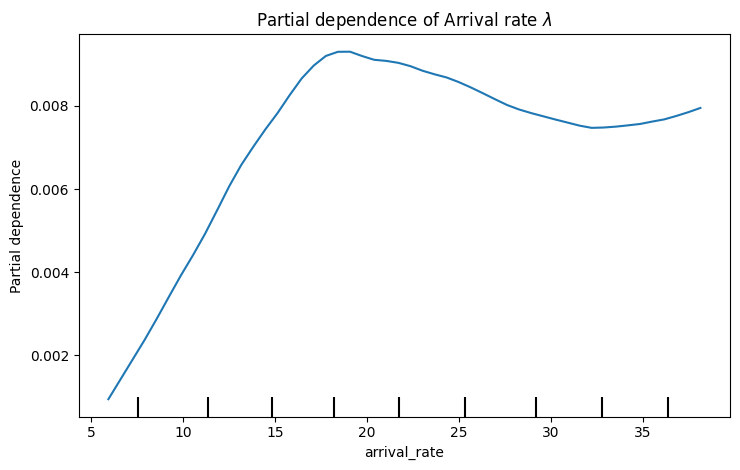

In [31]:
plot_single_partial_dependence(
    nn_model,
    X_test,
    "arrival_rate"
)

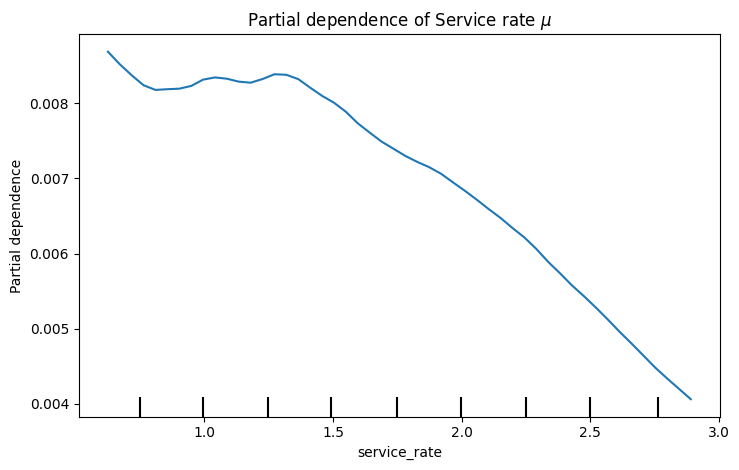

In [32]:
plot_single_partial_dependence(
    nn_model,
    X_test,
    "service_rate"
)

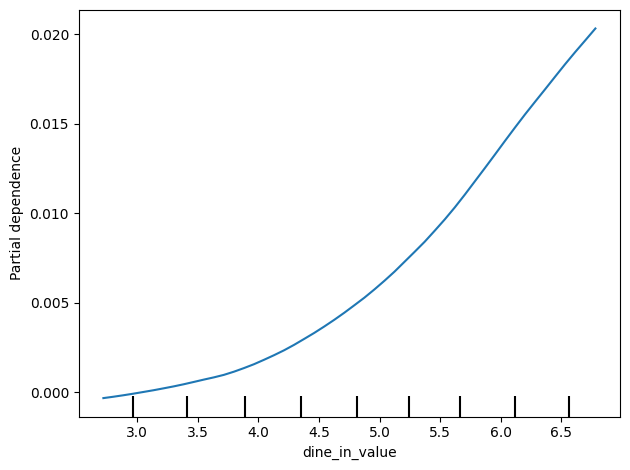

In [20]:
plot_single_partial_dependence(
    nn_model,
    X_test,
    "dine_in_value"
)

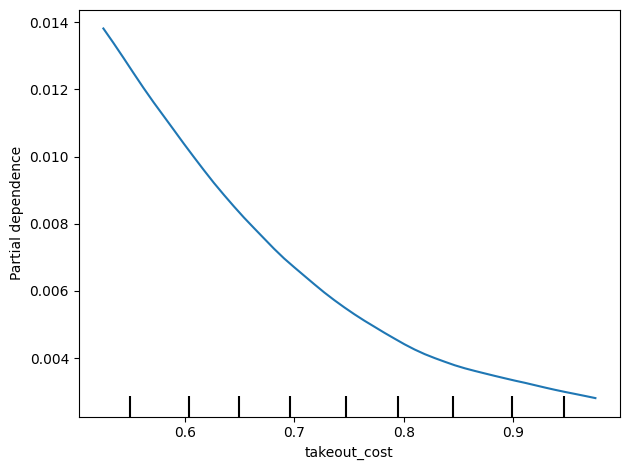

In [21]:
plot_single_partial_dependence(
    nn_model,
    X_test,
    "takeout_cost"
) ###????

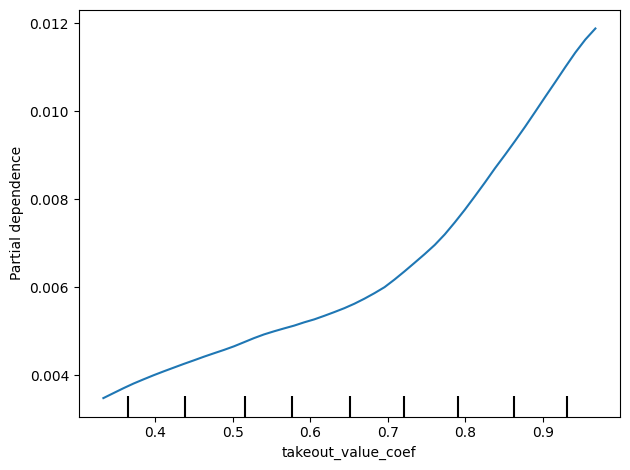

In [22]:
plot_single_partial_dependence(
    nn_model,
    X_test,
    "takeout_value_coef"
)

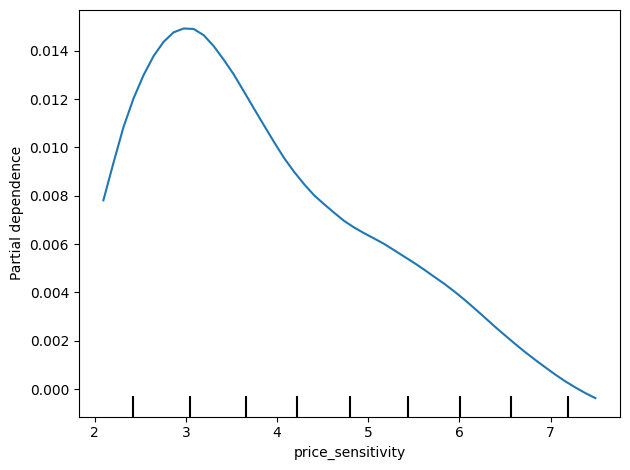

In [24]:
plot_single_partial_dependence(
    nn_model,
    X_test,
    "price_sensitivity"
)

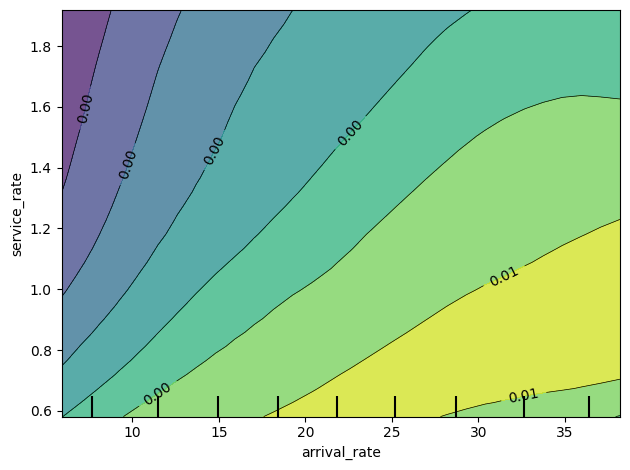

In [9]:
plot_interaction_partial_dependence(
    nn_model,
    X_test,
    "arrival_rate",
    "service_rate"
)